# 🏁 Milestone 1 — Formula 1 Podium Prediction Companion

**Team:** _TODO: names / IDs_ **Course:** CSEN 903 — Advanced Computer Lab (GUC, Winter 2026)

**Task:** predict whether a driver finishes on the podium (`positionOrder <= 3`) using only information available **after qualifying and before lights out**.

### How to read this notebook
| Marker | Meaning |
|---|---|
| ✅ | Mechanical / standard step — implemented, runs as-is. |
| 🟨 **DECISION** | A choice **you** must make and defend. The cell runs with a **naive placeholder** (marked `# TODO(decide)`) so *Run All* works end to end — replace it with your choice and justify it in the markdown below the cell. |
| ✍️ **WRITE-UP** | Interpretation you must write from the plots/numbers above it. |

Search the notebook for `TODO(decide)` and `✍️` to find every open item. Section 17 prints a **decision log** of all current choices for the report.

### Contents
1. Setup & configuration
2. Load raw tables (immutable)
3. Audit — sentinels, keys, grain (**before** cleaning)
4. EDA — before cleaning
5. Cleaning — sentinels, semantic typing, categorical hygiene, duplicates
6. Audit & EDA — after cleaning (before/after comparison)
7. Data-engineering questions (Q1–Q3)
8. Modeling table — one row per (raceId, driverId), leakage-safe features
9. Feature selection evidence
10. Train / validation / test split
11. Preprocessing & preprocessing-order experiments
12. Evaluation harness
13. Models — baseline, statistical models, shallow FFNN
14. Final evaluation on the unseen test set
15. Feature-group ablation
16. Explainability (XAI)
17. Inference function
18. Decision log, limitations & report material

## 1. Setup & configuration ✅

In [2]:
import os, sys, re, glob, json, warnings, subprocess, importlib
from pathlib import Path

def _ensure(pkg, pip_name=None):
    # Install a package if missing (Kaggle needs Internet = ON in the notebook settings).
    try:
        return importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or pkg], check=False)
        return importlib.import_module(pkg)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, roc_curve, precision_recall_curve, confusion_matrix,
                             ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__)

python 3.12.12 | pandas 3.0.6 | numpy 2.5.4


In [3]:
# ---- Data location: auto-detect Kaggle input, else ./data --------------------------
KAGGLE_DEFAULT = Path("/kaggle/input/formula-1-world-championship-1950-2020")

def find_data_dir():
    if (KAGGLE_DEFAULT / "races.csv").exists():
        return KAGGLE_DEFAULT
    hits = glob.glob("/kaggle/input/**/races.csv", recursive=True)
    if hits:
        return Path(hits[0]).parent
    for cand in [Path("data"), Path("../data"), Path(".")]:
        if (cand / "races.csv").exists():
            return cand
    raise FileNotFoundError("races.csv not found: attach the Kaggle dataset or put the CSVs in ./data")

DATA_DIR = Path(os.environ["F1_DATA_DIR"]) if os.environ.get("F1_DATA_DIR") else find_data_dir()
OUT_DIR = Path("outputs"); FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def savefig(name, fig=None):
    # Save the current figure for the PDF report, then show it.
    fig = fig or plt.gcf()
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)
    plt.show()
    plt.close(fig)

print("DATA_DIR =", DATA_DIR.resolve())
print("Figures ->", FIG_DIR.resolve())

DATA_DIR = C:\Users\moham\OneDrive\Desktop\Aeyyy cee ellll\data
Figures -> C:\Users\moham\OneDrive\Desktop\Aeyyy cee ellll\outputs\figures


## 2. Load raw tables ✅
All 14 CSVs are read **as strings** with `keep_default_na=False`, so nothing is silently converted: the literal `\N` sentinels stay visible for the audit. `RAW` is never modified — every cleaning step works on copies (`T`).

In [4]:
TABLES = ["circuits", "constructor_results", "constructor_standings", "constructors",
          "driver_standings", "drivers", "lap_times", "pit_stops", "qualifying",
          "races", "results", "seasons", "sprint_results", "status"]

RAW = {t: pd.read_csv(DATA_DIR / f"{t}.csv", dtype=str, keep_default_na=False) for t in TABLES}

overview = pd.DataFrame({t: {"rows": len(df), "cols": df.shape[1], "columns": ", ".join(df.columns)}
                         for t, df in RAW.items()}).T
overview

,rows,cols,columns
circuits,77,9,"circuitId, circuitRef, name, location, country..."
constructor_results,12625,5,"constructorResultsId, raceId, constructorId, p..."
constructor_standings,13391,7,"constructorStandingsId, raceId, constructorId,..."
constructors,212,5,"constructorId, constructorRef, name, nationali..."
driver_standings,34863,7,"driverStandingsId, raceId, driverId, points, p..."
drivers,861,9,"driverId, driverRef, number, code, forename, s..."
lap_times,589081,6,"raceId, driverId, lap, position, time, millise..."
pit_stops,11371,7,"raceId, driverId, stop, lap, time, duration, m..."
qualifying,10494,9,"qualifyId, raceId, driverId, constructorId, nu..."
races,1125,18,"raceId, year, round, circuitId, name, date, ti..."


## 3. Audit — before cleaning ✅
### 3.1 Sentinel scan
We look for every token that *means* missing but isn't `NaN`: the Ergast `\N`, empty strings, and whitespace-only cells. We also flag string values with leading/trailing whitespace — a classic source of silent join failures.

In [5]:
SENTINELS = {r"\N", "", "NULL", "null", "NaN", "nan", "None"}

def sentinel_report(tables):
    rows = []
    for t, df in tables.items():
        for c in df.columns:
            s = df[c].astype("string")
            is_sent = s.isin(SENTINELS) | s.str.strip().eq("")
            ws = s.notna() & s.ne(s.str.strip()) & ~is_sent
            rows.append({"table": t, "column": c, "n": len(s),
                         "sentinel_count": int(is_sent.sum()),
                         "sentinel_pct": round(100 * is_sent.mean(), 2) if len(s) else 0.0,
                         "untrimmed_whitespace": int(ws.sum()),
                         "tokens": ", ".join(sorted(set(s[is_sent].dropna().unique())))})
    return pd.DataFrame(rows)

sent_before = sentinel_report(RAW)
sent_before.query("sentinel_count > 0 or untrimmed_whitespace > 0").sort_values("sentinel_pct", ascending=False)

,table,column,n,sentinel_count,sentinel_pct,untrimmed_whitespace,tokens
13,constructor_results,status,12625,12608,99.87,0,\N
81,races,sprint_time,1125,1110,98.67,0,\N
80,races,sprint_date,1125,1107,98.40,0,\N
77,races,fp3_time,1125,1072,95.29,0,\N
79,races,quali_time,1125,1057,93.96,0,\N
75,races,fp2_time,1125,1057,93.96,0,\N
73,races,fp1_time,1125,1057,93.96,0,\N
76,races,fp3_date,1125,1053,93.60,0,\N
35,drivers,number,861,802,93.15,0,\N
78,races,quali_date,1125,1035,92.00,0,\N


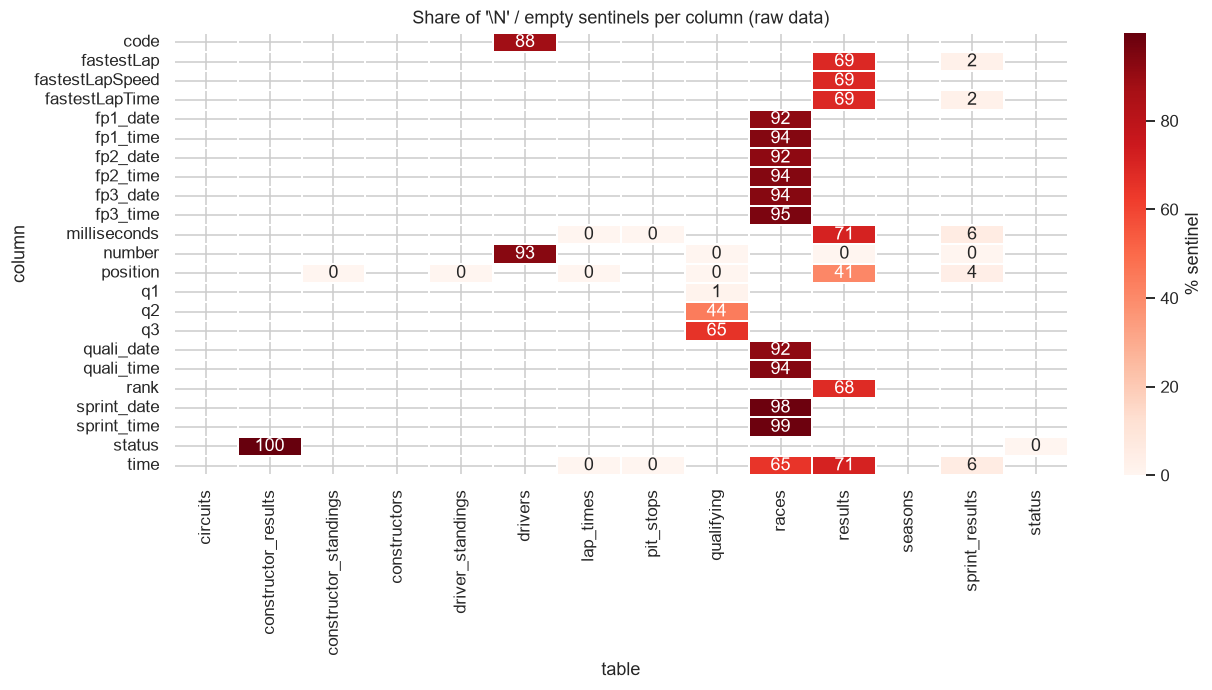

In [6]:
piv = sent_before.pivot_table(index="column", columns="table", values="sentinel_pct")
piv = piv.loc[piv.max(axis=1) > 0]
plt.figure(figsize=(12, max(4, 0.28 * len(piv))))
sns.heatmap(piv, cmap="Reds", annot=True, fmt=".0f", cbar_kws={"label": "% sentinel"}, linewidths=.3)
plt.title(r"Share of '\N' / empty sentinels per column (raw data)")
plt.tight_layout(); savefig("audit_sentinels_heatmap")

### 3.2 Primary keys and foreign keys
- **PK check:** unique **and** non-null (sentinels count as null).
- **Natural-grain check:** the business key each table *should* be unique on (e.g. results should be unique per `(raceId, driverId)`).
- **FK check:** every child value must exist in the parent table. Null FKs are reported separately from orphans.

In [7]:
PRIMARY_KEYS = {
    "circuits": ["circuitId"], "constructor_results": ["constructorResultsId"],
    "constructor_standings": ["constructorStandingsId"], "constructors": ["constructorId"],
    "driver_standings": ["driverStandingsId"], "drivers": ["driverId"],
    "lap_times": ["raceId", "driverId", "lap"], "pit_stops": ["raceId", "driverId", "stop"],
    "qualifying": ["qualifyId"], "races": ["raceId"], "results": ["resultId"],
    "seasons": ["year"], "sprint_results": ["resultId"], "status": ["statusId"],
}
NATURAL_KEYS = {
    "results": ["raceId", "driverId"], "qualifying": ["raceId", "driverId"],
    "sprint_results": ["raceId", "driverId"], "driver_standings": ["raceId", "driverId"],
    "constructor_standings": ["raceId", "constructorId"], "constructor_results": ["raceId", "constructorId"],
    "races": ["year", "round"],
}
FOREIGN_KEYS = [  # (child_table, child_col, parent_table, parent_col)
    ("races", "circuitId", "circuits", "circuitId"), ("races", "year", "seasons", "year"),
    *[(t, "raceId", "races", "raceId") for t in ["results", "qualifying", "sprint_results", "lap_times", "pit_stops",
                                                 "driver_standings", "constructor_standings", "constructor_results"]],
    *[(t, "driverId", "drivers", "driverId") for t in ["results", "qualifying", "sprint_results", "lap_times",
                                                       "pit_stops", "driver_standings"]],
    *[(t, "constructorId", "constructors", "constructorId") for t in ["results", "qualifying", "sprint_results",
                                                                      "constructor_standings", "constructor_results"]],
    ("results", "statusId", "status", "statusId"), ("sprint_results", "statusId", "status", "statusId"),
]

def _null(s):
    return s.isna() | s.astype("string").isin(SENTINELS)

def key_report(tables, keys, label):
    rows = []
    for t, cols in keys.items():
        df = tables[t]
        null_rows = df[cols].apply(_null).any(axis=1)
        dup_rows = df.duplicated(cols, keep=False)
        rows.append({"table": t, "key": "+".join(cols), "check": label, "rows": len(df),
                     "null_key_rows": int(null_rows.sum()), "duplicate_key_rows": int(dup_rows.sum()),
                     "ok": bool(null_rows.sum() == 0 and dup_rows.sum() == 0)})
    return pd.DataFrame(rows)

def fk_report(tables):
    rows = []
    for ct, cc, pt, pc in FOREIGN_KEYS:
        child = tables[ct][cc]
        nulls = _null(child)
        parent_vals = set(tables[pt][pc].dropna().astype(str))
        orphan = ~nulls & ~child.astype(str).isin(parent_vals)
        rows.append({"child": f"{ct}.{cc}", "parent": f"{pt}.{pc}", "rows": len(child),
                     "null_fk": int(nulls.sum()), "orphans": int(orphan.sum()),
                     "example_orphans": ", ".join(child[orphan].astype(str).unique()[:5]),
                     "ok": bool(orphan.sum() == 0)})
    return pd.DataFrame(rows)

pk_before = pd.concat([key_report(RAW, PRIMARY_KEYS, "primary key"),
                       key_report(RAW, NATURAL_KEYS, "natural grain")], ignore_index=True)
fk_before = fk_report(RAW)
display(pk_before)
display(fk_before)

,table,key,check,rows,null_key_rows,duplicate_key_rows,ok
0,circuits,circuitId,primary key,77,0,0,True
1,constructor_results,constructorResultsId,primary key,12625,0,0,True
2,constructor_standings,constructorStandingsId,primary key,13391,0,0,True
3,constructors,constructorId,primary key,212,0,0,True
4,driver_standings,driverStandingsId,primary key,34863,0,0,True
5,drivers,driverId,primary key,861,0,0,True
6,lap_times,raceId+driverId+lap,primary key,589081,0,0,True
7,pit_stops,raceId+driverId+stop,primary key,11371,0,0,True
8,qualifying,qualifyId,primary key,10494,0,0,True
9,races,raceId,primary key,1125,0,0,True


,child,parent,rows,null_fk,orphans,example_orphans,ok
0,races.circuitId,circuits.circuitId,1125,0,0,,True
1,races.year,seasons.year,1125,0,0,,True
2,results.raceId,races.raceId,26759,0,0,,True
3,qualifying.raceId,races.raceId,10494,0,0,,True
4,sprint_results.raceId,races.raceId,360,0,0,,True
5,lap_times.raceId,races.raceId,589081,0,0,,True
6,pit_stops.raceId,races.raceId,11371,0,0,,True
7,driver_standings.raceId,races.raceId,34863,0,0,,True
8,constructor_standings.raceId,races.raceId,13391,0,0,,True
9,constructor_results.raceId,races.raceId,12625,0,0,,True


### 3.3 Grain: drivers appearing more than once in the same race ✅

176 result rows belong to 85 duplicated (raceId, driverId) pairs


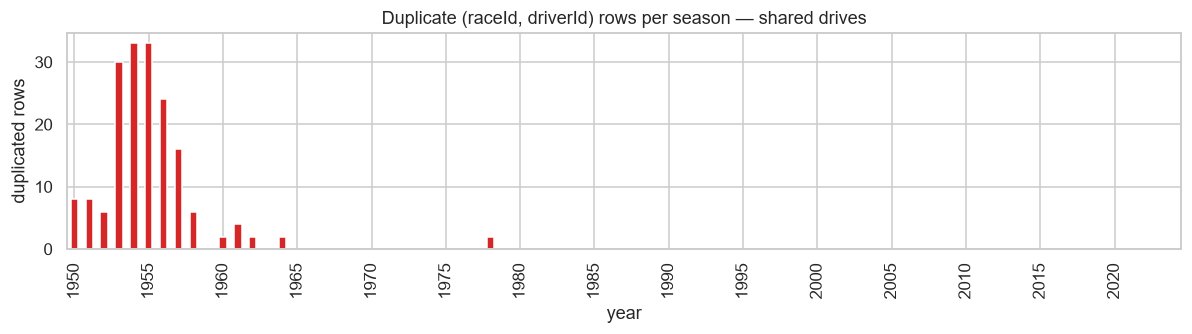

,year,raceId,driverId,constructorId,resultId,grid,positionOrder,points,laps,statusId
13188,1978,540,229,54,13189,0,26,0,0,81
13191,1978,540,229,57,13192,0,29,0,0,97
17362,1964,717,373,172,17363,1,7,0,102,60
24298,1964,717,373,172,24304,1,12,0,54,98
17740,1962,733,465,172,17741,0,22,0,0,54
17743,1962,733,465,97,17744,0,25,0,0,54
17961,1961,742,475,102,17962,20,19,0,56,2
17963,1961,742,475,172,17964,5,21,0,44,23
18062,1961,745,418,172,18063,11,17,0,23,6
24297,1961,745,418,172,24303,15,11,0,92,18


In [8]:
res_raw = RAW["results"].merge(RAW["races"][["raceId", "year"]], on="raceId", how="left")
dup_mask = res_raw.duplicated(["raceId", "driverId"], keep=False)
dups_raw = res_raw[dup_mask].sort_values(["raceId", "driverId", "resultId"])
print(f"{dup_mask.sum()} result rows belong to {dups_raw.groupby(['raceId','driverId']).ngroups} duplicated (raceId, driverId) pairs")

fig, ax = plt.subplots(figsize=(11, 3.2))
dups_raw.groupby("year").size().reindex(sorted(res_raw.year.unique()), fill_value=0).plot.bar(ax=ax, color="tab:red")
ax.set_xticks(ax.get_xticks()[::5]); ax.set_ylabel("duplicated rows"); ax.set_title("Duplicate (raceId, driverId) rows per season — shared drives")
plt.tight_layout(); savefig("audit_duplicates_per_year")

dups_raw[["year", "raceId", "driverId", "constructorId", "resultId", "grid", "positionOrder", "points", "laps", "statusId"]].head(12)

## 4. EDA — before cleaning ✅
Raw-data exploration that motivates the cleaning and later decisions. Values are coerced on the fly (`errors="coerce"`) only for plotting; `RAW` stays untouched.

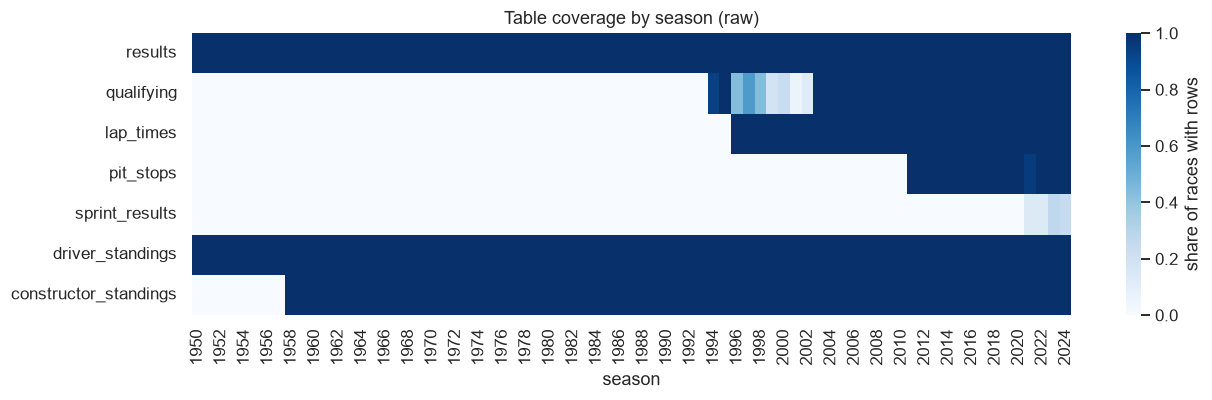

In [9]:
def num(s):  # temporary coercion for plots only
    return pd.to_numeric(s.replace(r"\N", np.nan), errors="coerce")

races_y = RAW["races"].assign(year=num(RAW["races"]["year"]))[["raceId", "year"]]

# Which tables actually have data in which seasons? (coverage drift)
cov = {}
for t in ["results", "qualifying", "lap_times", "pit_stops", "sprint_results", "driver_standings", "constructor_standings"]:
    cov[t] = RAW[t][["raceId"]].drop_duplicates().merge(races_y, on="raceId").groupby("year").size()
cov = pd.DataFrame(cov).reindex(sorted(races_y.year.dropna().unique())).fillna(0)
cov = cov.div(races_y.groupby("year").size(), axis=0)  # share of races covered

plt.figure(figsize=(12, 3.8))
sns.heatmap(cov.T, cmap="Blues", vmin=0, vmax=1, cbar_kws={"label": "share of races with rows"})
plt.title("Table coverage by season (raw)"); plt.xlabel("season")
plt.tight_layout(); savefig("eda_raw_table_coverage")

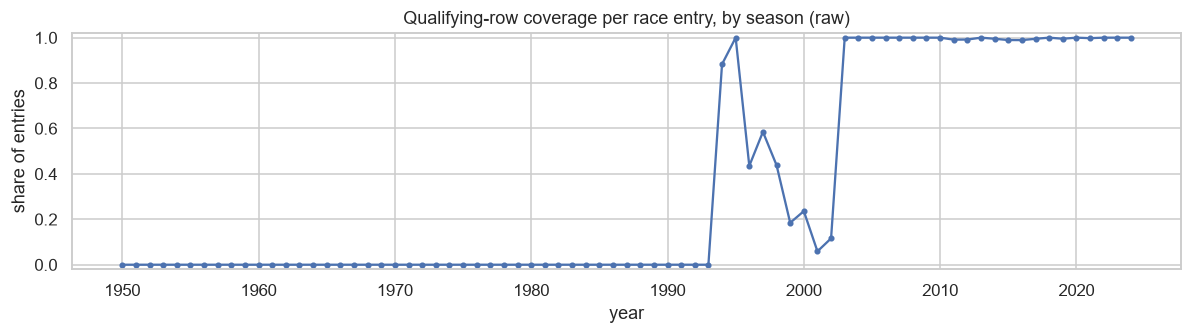

year,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
quali_coverage,0.0,0.0,0.0,0.0,0.88,1.0,0.44,0.59,0.44,0.18,0.24,0.06,0.12,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.99,0.99,1.0,1.0,0.99,0.99,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [10]:
# Qualifying coverage at the grain we care about: share of race entries that have a qualifying row
res_y = RAW["results"][["raceId", "driverId"]].merge(races_y, on="raceId")
qkeys = set(zip(RAW["qualifying"].raceId, RAW["qualifying"].driverId))
res_y["has_quali"] = [k in qkeys for k in zip(res_y.raceId, res_y.driverId)]
qcov = res_y.groupby("year").has_quali.mean()

fig, ax = plt.subplots(figsize=(11, 3.2))
qcov.plot(ax=ax, marker="o", ms=3); ax.set_ylim(-.02, 1.02)
ax.set_ylabel("share of entries"); ax.set_title("Qualifying-row coverage per race entry, by season (raw)")
plt.tight_layout(); savefig("eda_raw_quali_coverage")
qcov[qcov.index >= 1990].round(2).to_frame("quali_coverage").T

In [11]:
# Raw formats of duration-like strings: one regex "shape" per value, to see what the parser must handle
def shape(v):
    if v in SENTINELS: return "<sentinel>"
    return re.sub(r"\d", "9", v)

for t, c in [("qualifying", "q1"), ("results", "fastestLapTime"), ("pit_stops", "duration"),
             ("lap_times", "time"), ("results", "time")]:
    vc = RAW[t][c].map(shape).value_counts()
    print(f"{t}.{c}: {len(vc)} shapes ->", dict(vc.head(6)))

qualifying.q1: 3 shapes -> {'9:99.999': np.int64(10337), '<sentinel>': np.int64(156), '99:99.999': np.int64(1)}
results.fastestLapTime: 2 shapes -> {'<sentinel>': np.int64(18507), '9:99.999': np.int64(8252)}
pit_stops.duration: 3 shapes -> {'99.999': np.int64(10854), '99:99.999': np.int64(460), '9:99.999': np.int64(57)}
lap_times.time: 3 shapes -> {'9:99.999': np.int64(588455), '99:99.999': np.int64(583), '9:99:99.999': np.int64(43)}
results.time: 22 shapes -> {'<sentinel>': np.int64(19079), '+99.999': np.int64(2973), '+9:99.999': np.int64(1614), '9:99:99.999': np.int64(765), '+9.999': np.int64(732), '+9:99.99': np.int64(281)}


In [12]:
# Categorical hygiene: inconsistent spellings that would break joins (Q2 depends on these)
print("drivers.nationality :", sorted(RAW["drivers"].nationality.unique()))
print()
print("circuits.country   :", sorted(RAW["circuits"].country.unique()))

drivers.nationality : ['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Argentinian ', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']

circuits.country   : ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']


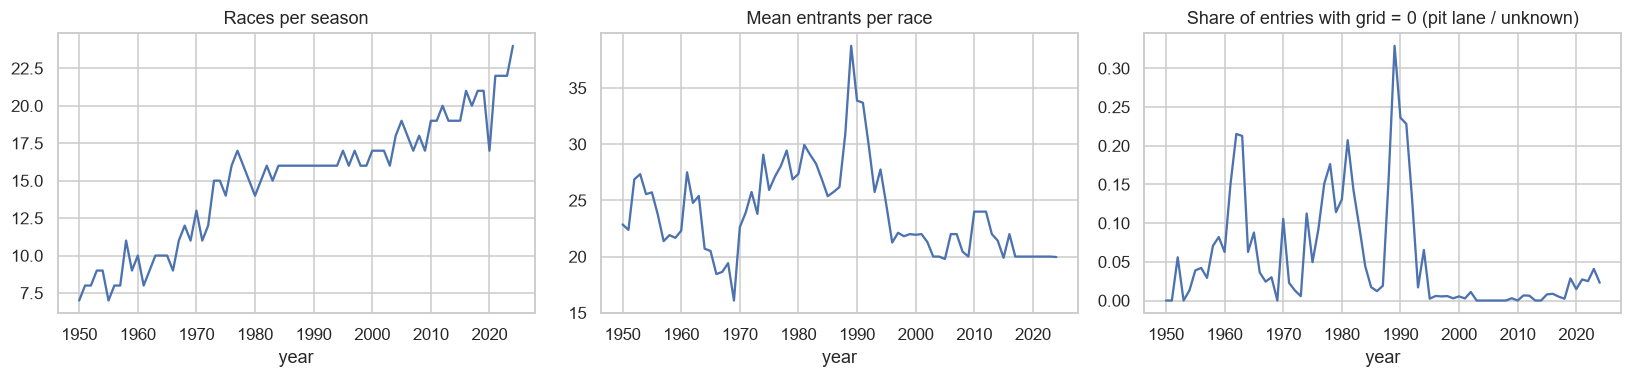

In [13]:
res_num = RAW["results"].assign(**{c: num(RAW["results"][c]) for c in ["grid", "positionOrder", "points"]}).merge(races_y, on="raceId")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
res_num.groupby("year").raceId.nunique().plot(ax=axes[0], title="Races per season")
res_num.groupby(["year", "raceId"]).size().groupby("year").mean().plot(ax=axes[1], title="Mean entrants per race")
(res_num.grid == 0).groupby(res_num.year).mean().plot(ax=axes[2], title="Share of entries with grid = 0 (pit lane / unknown)")
plt.tight_layout(); savefig("eda_raw_season_overview")

✍️ **WRITE-UP (EDA before cleaning):** summarise what the plots above show — which columns are mostly sentinels and why (structural vs. truly missing), when qualifying / pit-stop / lap-time coverage starts, what string formats the parser must handle, inconsistent categories, and what `grid = 0` means. Each finding should point to a cleaning step in §5 or a decision in §8.

## 5. Cleaning ✅ (+ 🟨 decisions)
Order: copy → trim whitespace → sentinels to `NaN` → semantic typing (ints, floats, dates, durations in seconds) → categorical normalisation → grain fix.

In [14]:
T = {t: df.copy() for t, df in RAW.items()}   # cleaning happens on copies only

# 1) trim whitespace, 2) sentinels -> NaN
for t, df in T.items():
    for c in df.columns:
        s = df[c].astype("string").str.strip()
        T[t][c] = s.mask(s.isin(SENTINELS) | s.eq(""))

def parse_duration(s):
    # '1:27.452' -> 87.452 s, '1:34:50.616' -> 5690.616 s, '22.5' -> 22.5 s; unparsable -> NaN.
    s = s.astype("string")
    parts = s.str.split(":", expand=True)
    parts = parts.apply(lambda col: pd.to_numeric(col, errors="coerce"))
    n_parts = s.str.count(":").add(1)
    out = pd.Series(np.nan, index=s.index, dtype="float64")
    for n in [1, 2, 3]:
        m = n_parts.eq(n).fillna(False).to_numpy(bool)
        if not m.any():
            continue
        vals = parts.loc[m, list(range(n))].astype("float64").to_numpy(dtype="float64", na_value=np.nan)
        weights = np.array([60.0 ** (n - 1 - i) for i in range(n)])
        out.loc[m] = vals @ weights
    return out

SCHEMA = {  # table: {int: [...], float: [...], date: [...], duration: [...], tod: [...]}
    "circuits": {"int": ["circuitId", "alt"], "float": ["lat", "lng"]},
    "constructor_results": {"int": ["constructorResultsId", "raceId", "constructorId"], "float": ["points"]},
    "constructor_standings": {"int": ["constructorStandingsId", "raceId", "constructorId", "position", "wins"], "float": ["points"]},
    "constructors": {"int": ["constructorId"]},
    "driver_standings": {"int": ["driverStandingsId", "raceId", "driverId", "position", "wins"], "float": ["points"]},
    "drivers": {"int": ["driverId", "number"], "date": ["dob"]},
    "lap_times": {"int": ["raceId", "driverId", "lap", "position", "milliseconds"], "duration": ["time"]},
    "pit_stops": {"int": ["raceId", "driverId", "stop", "lap", "milliseconds"], "duration": ["duration"], "tod": ["time"]},
    "qualifying": {"int": ["qualifyId", "raceId", "driverId", "constructorId", "number", "position"], "duration": ["q1", "q2", "q3"]},
    "races": {"int": ["raceId", "year", "round", "circuitId"],
              "date": ["date", "fp1_date", "fp2_date", "fp3_date", "quali_date", "sprint_date"],
              "tod": ["time", "fp1_time", "fp2_time", "fp3_time", "quali_time", "sprint_time"]},
    "results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position", "positionOrder",
                        "laps", "milliseconds", "fastestLap", "rank", "statusId"],
                "float": ["points", "fastestLapSpeed"], "duration": ["fastestLapTime"]},
    "seasons": {"int": ["year"]},
    "sprint_results": {"int": ["resultId", "raceId", "driverId", "constructorId", "number", "grid", "position",
                               "positionOrder", "laps", "milliseconds", "fastestLap", "statusId"],
                       "float": ["points"], "duration": ["fastestLapTime"]},
    "status": {"int": ["statusId"]},
}

for t, spec in SCHEMA.items():
    df = T[t]
    for c in spec.get("int", []):
        if c in df: df[c] = pd.to_numeric(df[c], errors="coerce").astype("Int64")
    for c in spec.get("float", []):
        if c in df: df[c] = pd.to_numeric(df[c], errors="coerce").astype("float64")
    for c in spec.get("date", []):
        if c in df: df[c] = pd.to_datetime(df[c], errors="coerce")
    for c in spec.get("duration", []):
        if c in df: df[f"{c}_sec"] = parse_duration(df[c])
    for c in spec.get("tod", []):
        if c in df: df[c] = pd.to_timedelta(df[c], errors="coerce")

# Typing must not invent new missing values: compare NaN counts with the sentinel audit
lost = []
for t, spec in SCHEMA.items():
    for kind in ["int", "float", "date"]:
        for c in spec.get(kind, []):
            if c in T[t]:
                raw_missing = _null(RAW[t][c]).sum(); now_missing = T[t][c].isna().sum()
                if now_missing != raw_missing:
                    lost.append((t, c, int(raw_missing), int(now_missing)))
    for c in spec.get("duration", []):
        if c in T[t]:
            raw_missing = _null(RAW[t][c]).sum(); now_missing = T[t][f"{c}_sec"].isna().sum()
            if now_missing != raw_missing:
                lost.append((t, f"{c}_sec", int(raw_missing), int(now_missing)))
pd.DataFrame(lost, columns=["table", "column", "missing_raw", "missing_after_typing"])  # should be empty or explained

,table,column,missing_raw,missing_after_typing


✍️ If the table above is non-empty, inspect those values (they failed to parse) and explain them. Note that `results.time` is deliberately kept as text: it mixes absolute race time and gaps (`+5.478`), and it is post-race information anyway.

In [15]:
# Categorical normalisation (found in §4): stray spellings that would break the home-race join in Q2
NATIONALITY_FIX = {"Argentinian": "Argentine"}
COUNTRY_FIX = {"United States": "USA", "United Kingdom": "UK", "Great Britain": "UK"}
T["drivers"]["nationality"] = T["drivers"]["nationality"].replace(NATIONALITY_FIX)
T["circuits"]["country"] = T["circuits"]["country"].replace(COUNTRY_FIX)
print(sorted(T["drivers"].nationality.dropna().unique()))

['American', 'American-Italian', 'Argentine', 'Argentine-Italian', 'Australian', 'Austrian', 'Belgian', 'Brazilian', 'British', 'Canadian', 'Chilean', 'Chinese', 'Colombian', 'Czech', 'Danish', 'Dutch', 'East German', 'Finnish', 'French', 'German', 'Hungarian', 'Indian', 'Indonesian', 'Irish', 'Italian', 'Japanese', 'Liechtensteiner', 'Malaysian', 'Mexican', 'Monegasque', 'New Zealander', 'Polish', 'Portuguese', 'Rhodesian', 'Russian', 'South African', 'Spanish', 'Swedish', 'Swiss', 'Thai', 'Uruguayan', 'Venezuelan']


### 5.1 🟨 DECISION — grid = 0
`grid = 0` means the driver started from the pit lane (modern era) **or** the grid slot is unknown (early era). Decide how to represent it as a pre-race feature (e.g. `NaN` + flag, back of the grid = number of entrants, keep 0 + flag) and justify with the §4 plot.

In [16]:
# TODO(decide): grid = 0 handling. Placeholder: keep the raw value and add an explicit flag.
T["results"]["pitlane_start"] = (T["results"]["grid"] == 0).astype("Int64")
GRID_ZERO_RULE = "placeholder: keep 0 and add pitlane_start flag"

### 5.2 🟨 DECISION — duplicate (raceId, driverId) rows (shared drives)
The modelling table must have exactly one row per driver per race. Pick a rule for which row to keep and **justify it** — consider what the *target* means for a shared drive (whose podium was it?), and whether the rule could leak information (e.g. "keep the best finish" uses the outcome to choose the row). Alternatives: keep the earliest `resultId` (the original entry), keep the row with the most laps, keep the lowest `positionOrder`, drop the affected races entirely, …

In [17]:
def resolve_duplicates(results: pd.DataFrame) -> pd.DataFrame:
    # TODO(decide): replace with your rule. Placeholder = keep the earliest resultId per (raceId, driverId).
    return (results.sort_values("resultId")
                   .drop_duplicates(["raceId", "driverId"], keep="first"))

DUPLICATE_RULE = "placeholder: keep earliest resultId"

before = len(T["results"])
T["results_dedup"] = resolve_duplicates(T["results"])
removed = T["results"].loc[~T["results"].resultId.isin(T["results_dedup"].resultId)]
print(f"rows: {before} -> {len(T['results_dedup'])} (removed {len(removed)})")
assert not T["results_dedup"].duplicated(["raceId", "driverId"]).any(), "grain still not unique!"

# How does the rule affect the target? (podium rows among removed vs kept, for the affected pairs)
affected = T["results"].merge(removed[["raceId", "driverId"]].drop_duplicates(), on=["raceId", "driverId"])
affected.assign(kept=affected.resultId.isin(T["results_dedup"].resultId), podium=affected.positionOrder <= 3) \
        .groupby("kept").agg(rows=("resultId", "size"), podium_rows=("podium", "sum"))

rows: 26759 -> 26668 (removed 91)


,rows,podium_rows
kept,,
False,91,18
True,85,6


## 6. Audit & EDA — after cleaning ✅

In [18]:
CLEAN = {t: T[t] for t in TABLES}            # cleaned versions of the 14 tables
CLEAN_DEDUP = {**CLEAN, "results": T["results_dedup"]}

pk_after = pd.concat([key_report(CLEAN_DEDUP, PRIMARY_KEYS, "primary key"),
                      key_report(CLEAN_DEDUP, NATURAL_KEYS, "natural grain")], ignore_index=True)
fk_after = fk_report(CLEAN_DEDUP)

cmp = pk_before[["table", "key", "check", "duplicate_key_rows", "null_key_rows"]].merge(
      pk_after[["table", "key", "check", "duplicate_key_rows", "null_key_rows"]],
      on=["table", "key", "check"], suffixes=("_before", "_after"))
display(cmp)
display(fk_after[["child", "parent", "null_fk", "orphans", "ok"]])

,table,key,check,duplicate_key_rows_before,null_key_rows_before,duplicate_key_rows_after,null_key_rows_after
0,circuits,circuitId,primary key,0,0,0,0
1,constructor_results,constructorResultsId,primary key,0,0,0,0
2,constructor_standings,constructorStandingsId,primary key,0,0,0,0
3,constructors,constructorId,primary key,0,0,0,0
4,driver_standings,driverStandingsId,primary key,0,0,0,0
5,drivers,driverId,primary key,0,0,0,0
6,lap_times,raceId+driverId+lap,primary key,0,0,0,0
7,pit_stops,raceId+driverId+stop,primary key,0,0,0,0
8,qualifying,qualifyId,primary key,0,0,0,0
9,races,raceId,primary key,0,0,0,0


,child,parent,null_fk,orphans,ok
0,races.circuitId,circuits.circuitId,0,0,True
1,races.year,seasons.year,0,0,True
2,results.raceId,races.raceId,0,0,True
3,qualifying.raceId,races.raceId,0,0,True
4,sprint_results.raceId,races.raceId,0,0,True
5,lap_times.raceId,races.raceId,0,0,True
6,pit_stops.raceId,races.raceId,0,0,True
7,driver_standings.raceId,races.raceId,0,0,True
8,constructor_standings.raceId,races.raceId,0,0,True
9,constructor_results.raceId,races.raceId,0,0,True


In [19]:
# dtypes before vs after (semantic typing)
dtype_cmp = pd.concat([pd.DataFrame({"table": t, "column": RAW[t].columns, "raw_dtype": RAW[t].dtypes.astype(str).values,
                                     "clean_dtype": [str(CLEAN[t][c].dtype) for c in RAW[t].columns]})
                       for t in ["results", "qualifying", "races", "pit_stops", "drivers"]])
dtype_cmp

,table,column,raw_dtype,clean_dtype
0,results,resultId,str,Int64
1,results,raceId,str,Int64
2,results,driverId,str,Int64
3,results,constructorId,str,Int64
4,results,number,str,Int64
...,...,...,...,...
4,drivers,forename,str,string
5,drivers,surname,str,string
6,drivers,dob,str,datetime64[us]
7,drivers,nationality,str,string


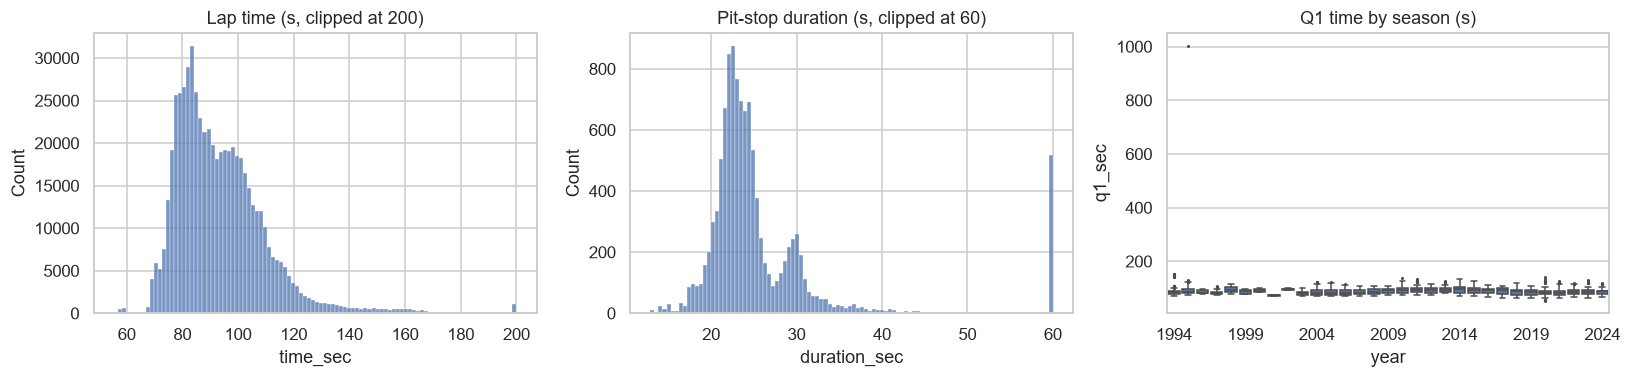

pit stops > 60 s (red flags / repairs): 517


In [20]:
# Distributions of the newly-typed duration columns — and the outliers they reveal
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
sns.histplot(CLEAN["lap_times"]["time_sec"].clip(upper=200), bins=100, ax=axes[0]); axes[0].set_title("Lap time (s, clipped at 200)")
sns.histplot(CLEAN["pit_stops"]["duration_sec"].clip(upper=60), bins=100, ax=axes[1]); axes[1].set_title("Pit-stop duration (s, clipped at 60)")
q = CLEAN["qualifying"].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
sns.boxplot(data=q, x="year", y="q1_sec", ax=axes[2], fliersize=1); axes[2].set_title("Q1 time by season (s)")
axes[2].set_xticks(axes[2].get_xticks()[::5])
plt.tight_layout(); savefig("eda_clean_durations")

print("pit stops > 60 s (red flags / repairs):", int((CLEAN["pit_stops"]["duration_sec"] > 60).sum()))

,table,column,sentinel_pct,nan_pct_after
13,constructor_results,status,99.87,99.87
81,races,sprint_time,98.67,98.67
80,races,sprint_date,98.40,98.40
77,races,fp3_time,95.29,95.29
73,races,fp1_time,93.96,93.96
75,races,fp2_time,93.96,93.96
79,races,quali_time,93.96,93.96
76,races,fp3_date,93.60,93.60
35,drivers,number,93.15,93.15
72,races,fp1_date,92.00,92.00


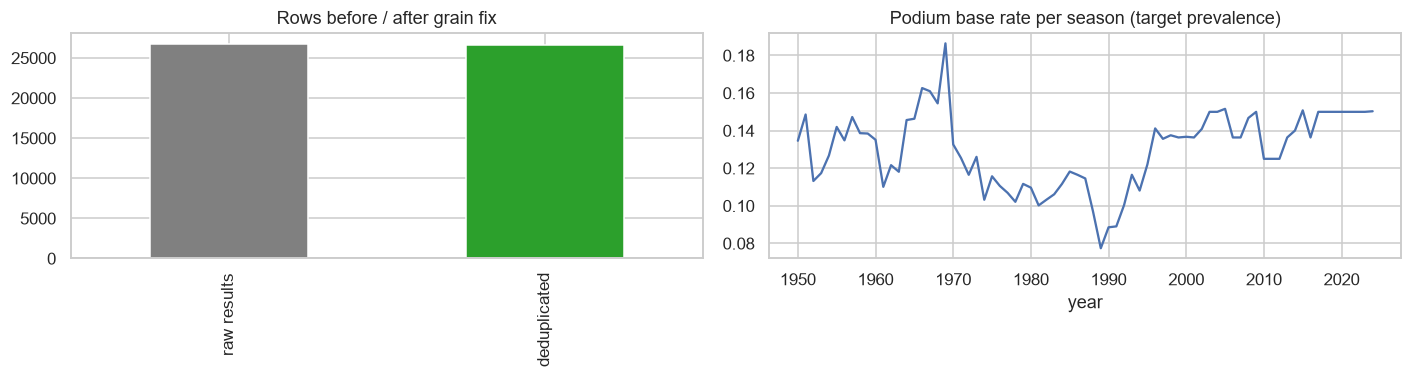

In [21]:
# Before vs after: missingness (sentinels -> NaN should match 1:1) and grain
after_missing = pd.DataFrame([{"table": t, "column": c, "nan_pct_after": round(100 * CLEAN[t][c].isna().mean(), 2)}
                              for t in TABLES for c in RAW[t].columns])
mm = sent_before.merge(after_missing, on=["table", "column"])
mm = mm.loc[(mm.sentinel_pct > 0) | (mm.nan_pct_after > 0), ["table", "column", "sentinel_pct", "nan_pct_after"]]
display(mm.sort_values("nan_pct_after", ascending=False).head(25))

res_c = CLEAN_DEDUP["results"].merge(CLEAN["races"][["raceId", "year"]], on="raceId")
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
pd.Series({"raw results": len(RAW["results"]), "deduplicated": len(res_c)}).plot.bar(ax=axes[0], color=["grey", "tab:green"])
axes[0].set_title("Rows before / after grain fix")
(res_c.positionOrder <= 3).groupby(res_c.year).mean().plot(ax=axes[1], title="Podium base rate per season (target prevalence)")
plt.tight_layout(); savefig("eda_clean_grain_and_base_rate")

✍️ **WRITE-UP (impact of cleaning):** what changed (dtypes, NaNs, rows removed, spelling fixes), which outliers the typed columns revealed, and the class imbalance (podium base rate) that drives the metric choice in §12.

## 7. Data-engineering questions
Shared joined view: results (deduplicated) ⨝ races ⨝ circuits ⨝ drivers ⨝ constructors ⨝ status ⨝ qualifying.

In [22]:
R = (CLEAN_DEDUP["results"][["resultId", "raceId", "driverId", "constructorId", "grid", "positionOrder", "statusId", "laps"]]
     .merge(CLEAN["races"][["raceId", "year", "round", "date", "circuitId"]], on="raceId", how="left")
     .merge(CLEAN["circuits"][["circuitId", "name", "country"]].rename(columns={"name": "circuit"}), on="circuitId", how="left")
     .merge(CLEAN["drivers"][["driverId", "driverRef", "nationality"]], on="driverId", how="left")
     .merge(CLEAN["constructors"][["constructorId", "name"]].rename(columns={"name": "constructor"}), on="constructorId", how="left")
     .merge(CLEAN["status"], on="statusId", how="left")
     .merge(CLEAN["qualifying"][["raceId", "driverId", "position"]].drop_duplicates(["raceId", "driverId"])
            .rename(columns={"position": "quali_pos"}), on=["raceId", "driverId"], how="left"))
R["podium"] = (R["positionOrder"] <= 3).astype(int)
assert R.duplicated(["raceId", "driverId"]).sum() == 0
print(R.shape); R.head()

(26668, 20)


,resultId,raceId,driverId,constructorId,grid,positionOrder,statusId,laps,year,round,date,circuitId,circuit,country,driverRef,nationality,constructor,status,quali_pos,podium
0,1,18,1,1,1,1,1,58,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,hamilton,British,McLaren,Finished,1,1
1,2,18,2,2,5,2,1,58,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,heidfeld,German,BMW Sauber,Finished,5,1
2,3,18,3,3,7,3,1,58,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,rosberg,German,Williams,Finished,7,1
3,4,18,4,4,11,4,1,58,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,alonso,Spanish,Renault,Finished,12,0
4,5,18,5,1,3,5,1,58,2008,1,2008-03-16,1,Albert Park Grand Prix Circuit,Australia,kovalainen,Finnish,McLaren,Finished,3,0


### Q1 — Which circuits convert a front-row start into a podium most often; does the ranking change after 2014?
Front row is measured two ways: **grid** (actual start, after penalties) and **qualifying position** (before penalties).

In [23]:
# 🟨 TODO(decide): era boundaries, minimum sample size, and which circuits are comparable across eras.
PRE_HYBRID = (2003, 2013)   # placeholder — note qualifying coverage is only complete from 2003 (see §4)
HYBRID = (2014, 2024)
Q1_MIN_STARTS = 8           # placeholder minimum front-row starts per circuit per era

def era_of(y):
    if PRE_HYBRID[0] <= y <= PRE_HYBRID[1]: return "pre-2014"
    if HYBRID[0] <= y <= HYBRID[1]: return "2014+"
    return None

R["era"] = R["year"].map(era_of)

def front_row_conversion(df, by):
    fr = df[df[by].isin([1, 2]) & df["era"].notna()]
    out = (fr.groupby(["circuit", "era"]).agg(starts=("podium", "size"), podiums=("podium", "sum"))
             .assign(rate=lambda d: d.podiums / d.starts).reset_index())
    return out[out.starts >= Q1_MIN_STARTS]

q1_grid = front_row_conversion(R, "grid")
q1_quali = front_row_conversion(R, "quali_pos")

# How often do grid and qualifying front rows differ? (penalties / pit-lane starts)
both = R[R.era.notna() & R.quali_pos.notna()]
diff = both[(both.quali_pos <= 2) != (both.grid.between(1, 2))]
print(f"Entries where 'front row' differs between grid and qualifying: {len(diff)} "
      f"({len(diff) / both.quali_pos.le(2).sum():.1%} of qualifying front rows)")
q1_grid.sort_values("rate", ascending=False).head(10)

Entries where 'front row' differs between grid and qualifying: 74 (8.6% of qualifying front rows)


,circuit,era,starts,podiums,rate
23,Circuit de Nevers Magny-Cours,pre-2014,12,11,0.916667
54,Suzuka Circuit,2014+,18,16,0.888889
17,Circuit Park Zandvoort,2014+,8,7,0.875000
36,Jeddah Corniche Circuit,2014+,8,7,0.875000
57,Yas Marina Circuit,2014+,22,19,0.863636
21,Circuit de Monaco,2014+,20,17,0.850000
24,Circuit de Spa-Francorchamps,2014+,22,18,0.818182
19,Circuit de Barcelona-Catalunya,2014+,22,18,0.818182
53,Sochi Autodrom,2014+,16,13,0.812500
26,Circuit of the Americas,2014+,20,16,0.800000


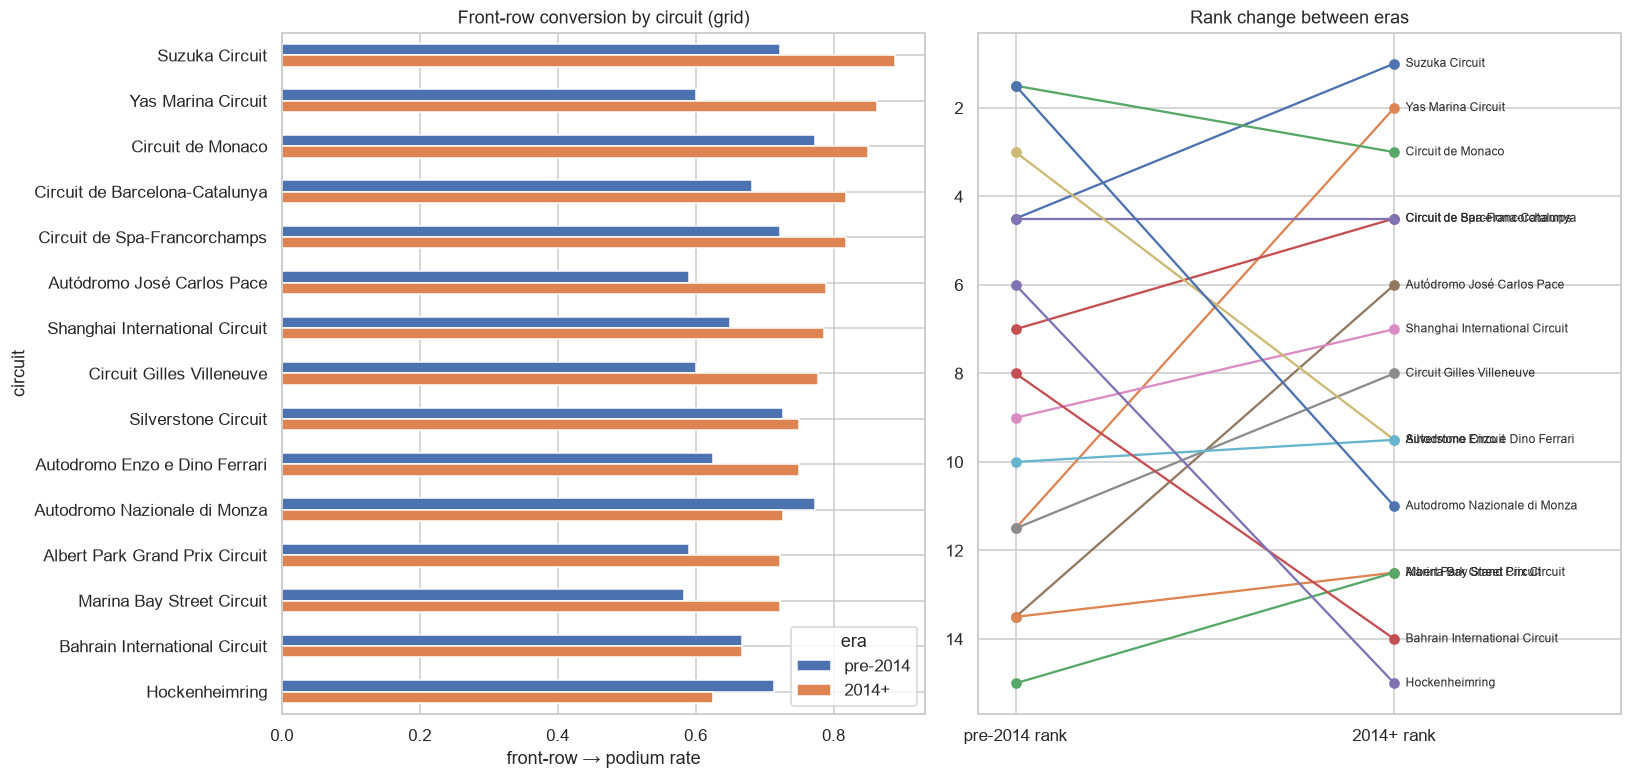

[grid] circuits in both eras: 15 | Spearman rank correlation pre vs 2014+: 0.21 (p=0.456)


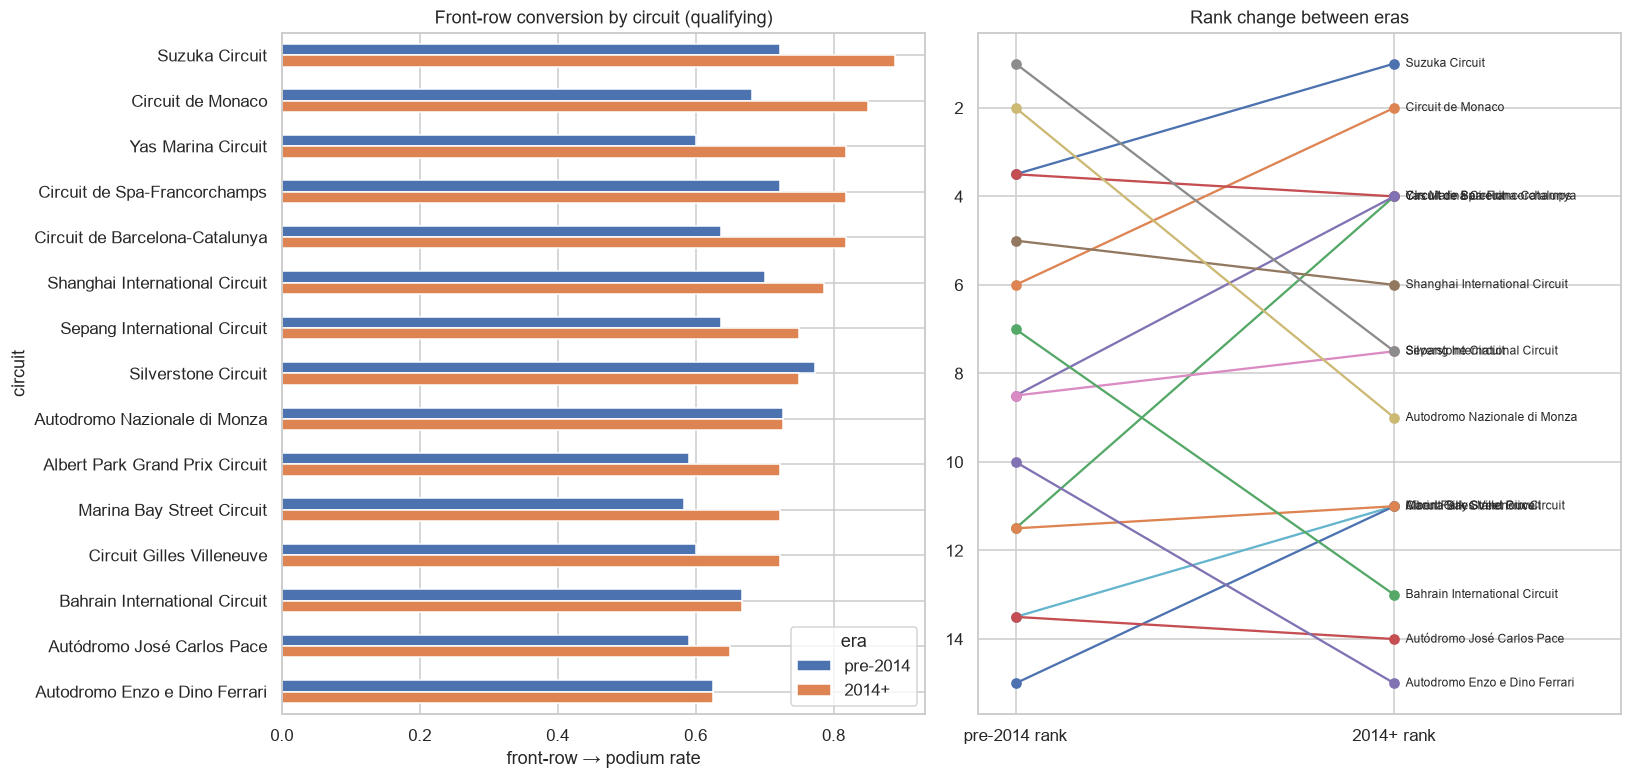

[qualifying] circuits in both eras: 15 | Spearman rank correlation pre vs 2014+: 0.50 (p=0.057)


In [24]:
def plot_q1(tbl, label, top=15):
    wide = tbl.pivot(index="circuit", columns="era", values="rate").dropna()
    wide = wide.sort_values("2014+", ascending=False).head(top)
    fig, axes = plt.subplots(1, 2, figsize=(15, 0.35 * len(wide) + 2))
    wide[["pre-2014", "2014+"]].plot.barh(ax=axes[0]); axes[0].invert_yaxis()
    axes[0].set_xlabel("front-row → podium rate"); axes[0].set_title(f"Front-row conversion by circuit ({label})")
    # slope chart of ranks
    ranks = wide.rank(ascending=False)
    for c, r in ranks.iterrows():
        axes[1].plot([0, 1], [r["pre-2014"], r["2014+"]], marker="o")
        axes[1].text(1.03, r["2014+"], c, va="center", fontsize=8)
    axes[1].set_xticks([0, 1], ["pre-2014 rank", "2014+ rank"]); axes[1].invert_yaxis(); axes[1].set_xlim(-.1, 1.6)
    axes[1].set_title("Rank change between eras")
    plt.tight_layout(); savefig(f"q1_front_row_{label}")
    rho, p = stats.spearmanr(wide["pre-2014"], wide["2014+"]) if len(wide) > 2 else (np.nan, np.nan)
    print(f"[{label}] circuits in both eras: {len(wide)} | Spearman rank correlation pre vs 2014+: {rho:.2f} (p={p:.3f})")

plot_q1(q1_grid, "grid")
plot_q1(q1_quali, "qualifying")

✍️ **WRITE-UP (Q1):** answer (top circuits per era), whether the ranking changes (Spearman ρ), how grid vs qualifying definitions differ, **grain** (one row per driver-race, filtered to front-row starters), **missingness** (qualifying coverage), and caveats (small samples per circuit, circuits that only exist in one era, layout changes).

### Q2 — Do drivers podium more often at home, controlling for starting position?
Home = the driver's nationality maps to the circuit's country. The comparison is made **within grid-position strata**, then pooled with a Mantel–Haenszel odds ratio.

In [25]:
# Nationality (demonym) -> circuit country, using Ergast's country spellings
NATIONALITY_TO_COUNTRY = {
    "American": "USA", "American-Italian": "USA", "Argentine": "Argentina", "Argentine-Italian": "Argentina",
    "Australian": "Australia", "Austrian": "Austria", "Belgian": "Belgium", "Brazilian": "Brazil",
    "British": "UK", "Canadian": "Canada", "Chilean": "Chile", "Chinese": "China", "Colombian": "Colombia",
    "Czech": "Czech Republic", "Danish": "Denmark", "Dutch": "Netherlands", "East German": "Germany",
    "Finnish": "Finland", "French": "France", "German": "Germany", "Hungarian": "Hungary", "Indian": "India",
    "Indonesian": "Indonesia", "Irish": "Ireland", "Italian": "Italy", "Japanese": "Japan",
    "Liechtensteiner": "Liechtenstein", "Malaysian": "Malaysia", "Mexican": "Mexico", "Monegasque": "Monaco",
    "New Zealander": "New Zealand", "Polish": "Poland", "Portuguese": "Portugal", "Rhodesian": "Zimbabwe",
    "Russian": "Russia", "South African": "South Africa", "Spanish": "Spain", "Swedish": "Sweden",
    "Swiss": "Switzerland", "Thai": "Thailand", "Uruguayan": "Uruguay", "Venezuelan": "Venezuela",
}
unmapped = sorted(set(R.nationality.dropna()) - set(NATIONALITY_TO_COUNTRY))
print("Unmapped nationalities:", unmapped or "none")

R["driver_country"] = R["nationality"].map(NATIONALITY_TO_COUNTRY)
R["home"] = (R["driver_country"] == R["country"]).astype(int)

# 🟨 TODO(decide): grid-position strata and the period analysed (and what to do with grid = 0).
Q2_GRID_BINS = [0, 1, 3, 6, 10, 15, 40]       # placeholder bins -> (0,1], (1,3], ...
Q2_PERIOD = (1950, 2024)                       # placeholder: all seasons

q2 = R[R.year.between(*Q2_PERIOD) & (R.grid > 0)].copy()
q2["grid_bin"] = pd.cut(q2.grid, Q2_GRID_BINS)
tab = q2.groupby(["grid_bin", "home"], observed=True).podium.agg(["mean", "size"]).unstack("home")
tab.columns = [f"{a}_{'home' if b else 'away'}" for a, b in tab.columns]
tab

Unmapped nationalities: none


,mean_away,mean_home,size_away,size_home
grid_bin,,,,
"(0, 1]",0.644101,0.569892,1034,93
"(1, 3]",0.508907,0.520231,2077,173
"(3, 6]",0.260186,0.242308,3117,260
"(6, 10]",0.092278,0.083333,4118,384
"(10, 15]",0.029653,0.031780,5126,472
"(15, 40]",0.007322,0.007439,7238,941


Crude odds ratio (home vs away):            0.79
Grid-adjusted Mantel-Haenszel odds ratio:   0.93  (95% CI 0.79-1.09)
Home entries: 2323 of 25033


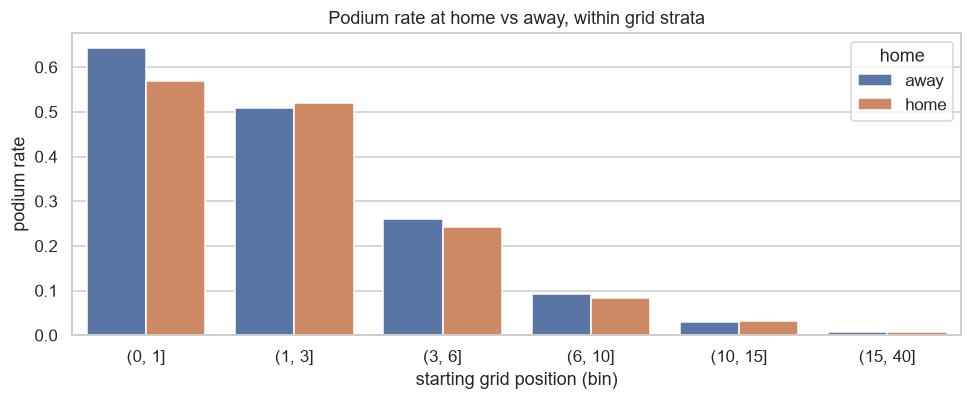

In [26]:
def mantel_haenszel(df, strata, exposure, outcome):
    # Pooled odds ratio across strata with Robins-Breslow-Greenland 95% CI.
    num = den = P_R = PS_QR = Q_S = 0.0
    sumR = sumS = 0.0
    for _, g in df.groupby(strata, observed=True):
        a = ((g[exposure] == 1) & (g[outcome] == 1)).sum(); b = ((g[exposure] == 1) & (g[outcome] == 0)).sum()
        c = ((g[exposure] == 0) & (g[outcome] == 1)).sum(); d = ((g[exposure] == 0) & (g[outcome] == 0)).sum()
        n = a + b + c + d
        if n == 0 or (a + b) == 0 or (c + d) == 0: continue
        Ri, Si = a * d / n, b * c / n
        Pi, Qi = (a + d) / n, (b + c) / n
        sumR += Ri; sumS += Si
        P_R += Pi * Ri; PS_QR += Pi * Si + Qi * Ri; Q_S += Qi * Si
    or_mh = sumR / sumS
    var = P_R / (2 * sumR**2) + PS_QR / (2 * sumR * sumS) + Q_S / (2 * sumS**2)
    lo, hi = np.exp(np.log(or_mh) + np.array([-1.96, 1.96]) * np.sqrt(var))
    return or_mh, lo, hi

crude_or = (lambda t: (t.loc[1, 1] * t.loc[0, 0]) / (t.loc[1, 0] * t.loc[0, 1]))(pd.crosstab(q2.home, q2.podium))
or_mh, lo, hi = mantel_haenszel(q2, "grid_bin", "home", "podium")
print(f"Crude odds ratio (home vs away):            {crude_or:.2f}")
print(f"Grid-adjusted Mantel-Haenszel odds ratio:   {or_mh:.2f}  (95% CI {lo:.2f}-{hi:.2f})")
print(f"Home entries: {q2.home.sum()} of {len(q2)}")

plot_df = q2.groupby(["grid_bin", "home"], observed=True).podium.mean().reset_index()
plot_df["home"] = plot_df.home.map({1: "home", 0: "away"})
plot_df["grid_bin"] = plot_df.grid_bin.astype(str)
plt.figure(figsize=(9, 3.8))
sns.barplot(data=plot_df, x="grid_bin", y="podium", hue="home")
plt.ylabel("podium rate"); plt.xlabel("starting grid position (bin)"); plt.title("Podium rate at home vs away, within grid strata")
plt.tight_layout(); savefig("q2_home_vs_away_by_grid")

✍️ **WRITE-UP (Q2):** crude vs adjusted effect and what the difference means (do home drivers just qualify better?), significance (CI), **grain**, **missingness** (unmapped nationalities, multi-nationality drivers, countries without a race), and limitations (nationality ≠ home; few home entries per stratum; Monaco/Monegasque etc.).

### Q3 — Mechanical-retirement rate by constructor: 2014–2021 vs 2022–2024
**Mechanical retirement** = a race **start** that ended because a car component failed — not crashes, driver errors or regulation decisions.

In [27]:
# All statuses that occur in the analysis window, so the classification is explicit and auditable
q3_window = R[R.year.between(2014, 2024)]
status_counts = q3_window.status.value_counts().rename_axis("status").reset_index(name="count")
print(", ".join(f"{s} ({n})" for s, n in status_counts.values))

Finished (2403), +1 Lap (1178), +2 Laps (208), Collision (150), Accident (85), Engine (81), Collision damage (59), Retired (50), Brakes (49), Gearbox (42), Power Unit (42), Suspension (25), +3 Laps (24), Hydraulics (15), Electrical (14), Withdrew (14), Power loss (13), Disqualified (11), Wheel (11), Spun off (11), Oil leak (10), Overheating (8), Mechanical (7), Water pressure (7), Puncture (7), Turbo (6), +4 Laps (6), ERS (5), Exhaust (5), Battery (5), Fuel pressure (5), Water leak (4), Electronics (4), Tyre (4), Undertray (4), Rear wing (3), Transmission (3), Front wing (3), Wheel nut (3), Radiator (3), Illness (3), +8 Laps (2), Oil pressure (2), Technical (2), Clutch (2), +6 Laps (2), Throttle (2), Vibrations (2), Driveshaft (2), Steering (2), Damage (2), Fuel leak (2), Drivetrain (1), Fuel system (1), Brake duct (1), Excluded (1), Seat (1), Spark plugs (1), Out of fuel (1), +5 Laps (1), Debris (1), Cooling system (1), Water pump (1), Fuel pump (1), Differential (1), +7 Laps (1)


In [28]:
# 🟨 TODO(decide): verify/complete these lists — this classification IS the answer to Q3. Justify edge cases.
CLEAR_MECHANICAL = {
    "Engine", "Gearbox", "Power Unit", "Hydraulics", "Electrical", "Brakes", "Suspension", "Power loss",
    "Oil leak", "Water pressure", "Overheating", "Mechanical", "Battery", "ERS", "Turbo", "Exhaust",
    "Fuel pressure", "Water leak", "Electronics", "Fuel system", "Transmission", "Throttle", "Radiator",
    "Oil pressure", "Clutch", "Driveshaft", "Steering", "Fuel leak", "Drivetrain", "Spark plugs",
    "Cooling system", "Water pump", "Fuel pump", "Differential", "Brake duct", "Oil pump",
}
AMBIGUOUS = {  # could be mechanical OR caused by contact/driver/team — decide each one
    "Retired", "Technical", "Wheel", "Wheel nut", "Puncture", "Tyre", "Rear wing", "Front wing", "Undertray",
    "Vibrations", "Vibration", "Handling", "Seat", "Damage", "Debris", "Out of fuel", "Safety switch",
}
MECHANICAL_STATUSES = CLEAR_MECHANICAL            # TODO(decide): add the ambiguous ones you judge mechanical
NOT_A_START = {"Did not start", "Withdrew", "Did not qualify", "Did not prequalify", "Not classified",
               "Excluded", "107% Rule"}           # TODO(decide): what counts as a 'race start' (denominator)?

unclassified = sorted(set(status_counts.status) - CLEAR_MECHANICAL - AMBIGUOUS - NOT_A_START)
print("Statuses not in any list (finished, +N laps, crashes, DSQ, ...):", unclassified)

Statuses not in any list (finished, +N laps, crashes, DSQ, ...): ['+1 Lap', '+2 Laps', '+3 Laps', '+4 Laps', '+5 Laps', '+6 Laps', '+7 Laps', '+8 Laps', 'Accident', 'Collision', 'Collision damage', 'Disqualified', 'Finished', 'Illness', 'Spun off']


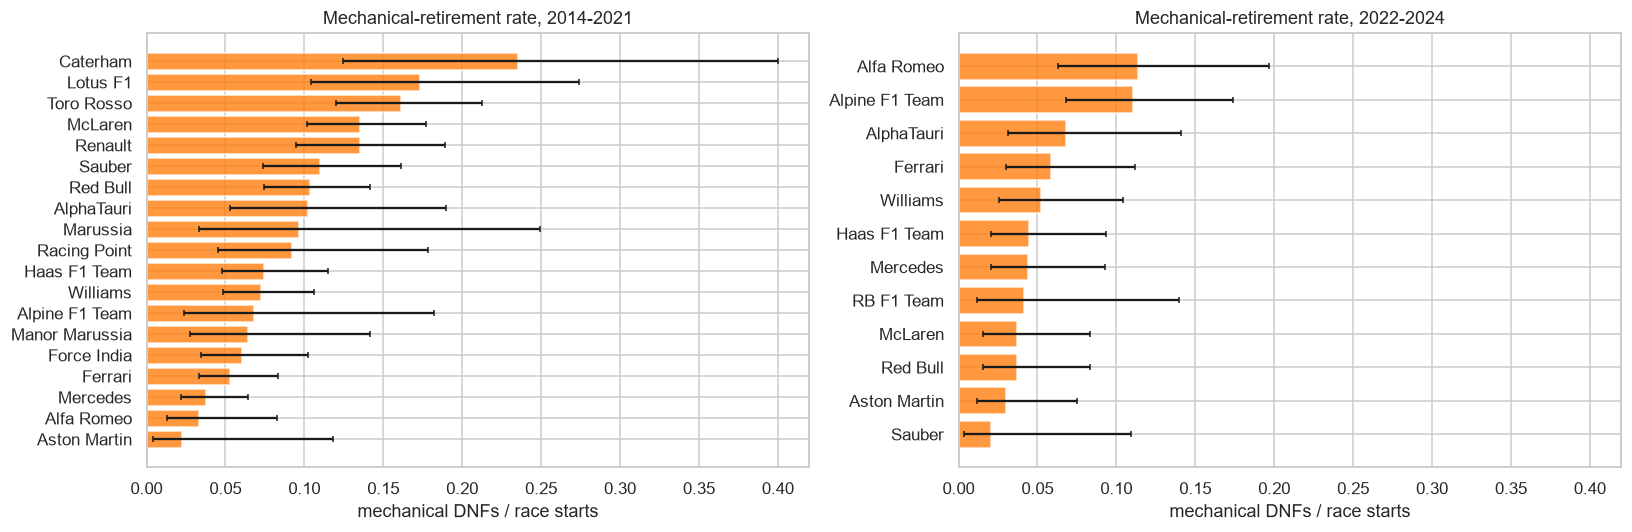

era,2014-2021,2022-2024
constructor,,
Alfa Romeo,0.033333,0.113636
Alpine F1 Team,0.068182,0.110294
AlphaTauri,0.102564,0.068182
Ferrari,0.053125,0.058824
Williams,0.072327,0.052239
Haas F1 Team,0.074689,0.044444
Mercedes,0.037500,0.044118
RB F1 Team,NaN,0.041667
Red Bull,0.103448,0.036765


In [29]:
Q3_ERAS = {"2014-2021": (2014, 2021), "2022-2024": (2022, 2024)}
Q3_MIN_STARTS = 20   # 🟨 TODO(decide) minimum starts per constructor per era

rows = []
for era, (a, b) in Q3_ERAS.items():
    w = R[R.year.between(a, b) & ~R.status.isin(NOT_A_START)]
    g = w.assign(mech=w.status.isin(MECHANICAL_STATUSES)).groupby("constructor").agg(starts=("mech", "size"), mech_dnf=("mech", "sum"))
    rows.append(g.assign(era=era, rate=g.mech_dnf / g.starts).reset_index())
q3 = pd.concat(rows)
q3 = q3[q3.starts >= Q3_MIN_STARTS]

# Wilson 95% interval per rate (small denominators matter here)
z = 1.96
p, n = q3.rate, q3.starts
centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
q3["lo"], q3["hi"] = centre - half, centre + half

fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, era in zip(axes, Q3_ERAS):
    d = q3[q3.era == era].sort_values("rate")
    ax.barh(d.constructor, d.rate, xerr=[d.rate - d.lo, d.hi - d.rate], color="tab:orange", alpha=.8, capsize=2)
    ax.set_title(f"Mechanical-retirement rate, {era}"); ax.set_xlabel("mechanical DNFs / race starts")
plt.tight_layout(); savefig("q3_mechanical_dnf_rate")
q3.pivot(index="constructor", columns="era", values="rate").sort_values("2022-2024", ascending=False)

✍️ **WRITE-UP (Q3):** highest-rate constructors in each era, how you classified statuses (and why the ambiguous ones went where they did), the denominator definition, **grain** (one row per start), constructor renames across eras (e.g. teams that changed name), and uncertainty (CIs).

## 8. Modeling table — one row per (raceId, driverId) ✅ (+ 🟨 decisions)
**Prediction cutoff:** after qualifying, before the race starts. Everything below is built with *strictly earlier* races only (`shift(1)` on a chronological order), or from the current race's **qualifying/grid**, which is known at the cutoff.

Forbidden (post-race) fields from the current race: `position`, `positionText`, `positionOrder` (except to build the target), `points`, `laps`, `time`, `milliseconds`, `fastestLap*`, `rank`, `statusId`, pit stops, lap times, and **standings published after this race**.

In [30]:
FORM_WINDOW = 5          # 🟨 TODO(decide): rolling window (races) for form features
MODEL_YEAR_MIN = 2003    # 🟨 TODO(decide): first season in the modelling table (see qualifying coverage in §4)
MODEL_YEAR_MAX = 2024

FINISHED_RE = r"^(Finished|\+\d+ Laps?)$"

base = (CLEAN_DEDUP["results"][["resultId", "raceId", "driverId", "constructorId", "grid", "pitlane_start", "positionOrder", "points", "statusId"]]
        .merge(CLEAN["races"][["raceId", "year", "round", "date", "circuitId"]], on="raceId")
        .merge(CLEAN["status"], on="statusId", how="left")
        .sort_values(["date", "raceId", "driverId"]).reset_index(drop=True))
base["podium"] = (base.positionOrder <= 3).astype(int)
base["finished"] = base.status.str.match(FINISHED_RE).fillna(False).astype(int)
# NOTE: positionOrder, points, status and finished are used ONLY (a) as the target and (b) shifted into past-only features.
print(base.shape)

(26668, 16)


In [31]:
# ---- Grid & qualifying features (known at the cutoff) -------------------------------
quali = CLEAN["qualifying"].drop_duplicates(["raceId", "driverId"]).copy()
quali["q_best_sec"] = quali[["q1_sec", "q2_sec", "q3_sec"]].min(axis=1)
quali["pole_sec"] = quali.groupby("raceId").q_best_sec.transform("min")
quali["gap_to_pole_sec"] = quali.q_best_sec - quali.pole_sec
quali["gap_to_pole_pct"] = 100 * quali.gap_to_pole_sec / quali.pole_sec
quali["reached_q3"] = quali.q3_sec.notna().astype(int)
quali["reached_q2"] = quali.q2_sec.notna().astype(int)
QUALI_COLS = ["quali_pos", "q_best_sec", "gap_to_pole_sec", "gap_to_pole_pct", "reached_q2", "reached_q3"]
quali = quali.rename(columns={"position": "quali_pos"})[["raceId", "driverId", *QUALI_COLS]]

df = base.merge(quali, on=["raceId", "driverId"], how="left")
df["grid_minus_quali"] = df.grid - df.quali_pos            # grid penalties / pit-lane starts
df["n_entrants"] = df.groupby("raceId").driverId.transform("size")

In [32]:
# ---- Pre-race standings: standings AFTER THE PREVIOUS ROUND of the same season --------
races_sorted = CLEAN["races"][["raceId", "year", "round"]].sort_values(["year", "round"])
races_sorted["prev_raceId"] = races_sorted.groupby("year").raceId.shift(1)   # NaN for round 1
df = df.merge(races_sorted[["raceId", "prev_raceId"]], on="raceId", how="left")

ds = CLEAN["driver_standings"][["raceId", "driverId", "points", "position", "wins"]].rename(
    columns={"raceId": "prev_raceId", "points": "drv_pts_before", "position": "drv_rank_before", "wins": "drv_wins_before"})
cs = CLEAN["constructor_standings"][["raceId", "constructorId", "points", "position", "wins"]].rename(
    columns={"raceId": "prev_raceId", "points": "con_pts_before", "position": "con_rank_before", "wins": "con_wins_before"})
df["prev_raceId"] = df.prev_raceId.astype("Int64")
df = df.merge(ds, on=["prev_raceId", "driverId"], how="left").merge(cs, on=["prev_raceId", "constructorId"], how="left")
df["is_round_1"] = df.prev_raceId.isna().astype(int)
# 🟨 TODO(decide): round 1 has no pre-race standings — leave NaN (imputer), fill 0, or carry last season's final standings?

In [33]:
# ---- Form features: rolling over the driver's / constructor's PREVIOUS races only -----
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
W = FORM_WINDOW

def past_rolling(g, col, w, how="mean"):
    s = g[col].astype("float64").shift(1)  # shift(1) => the current race is never included
    return s.rolling(w, min_periods=1).agg(how)

gd = df.groupby("driverId", group_keys=False)
df["drv_avg_finish_lastN"] = gd.apply(lambda g: past_rolling(g, "positionOrder", W))
df["drv_podium_rate_lastN"] = gd.apply(lambda g: past_rolling(g, "podium", W))
df["drv_finish_rate_lastN"] = gd.apply(lambda g: past_rolling(g, "finished", W))
df["drv_points_lastN"] = gd.apply(lambda g: past_rolling(g, "points", W, "sum"))
df["drv_career_starts"] = gd.cumcount()                                           # races before this one
df["drv_career_podiums"] = gd.apply(lambda g: g.podium.shift(1).fillna(0).cumsum())

# Constructor form: aggregate to one row per (constructor, race) FIRST so team-mates' current results can't leak
con_race = (df.groupby(["constructorId", "raceId", "date"], as_index=False)
              .agg(con_best_finish=("positionOrder", "min"), con_podiums=("podium", "sum"), con_points=("points", "sum"))
              .sort_values(["date", "raceId"]))
gc = con_race.groupby("constructorId", group_keys=False)
con_race["con_best_finish_lastN"] = gc.apply(lambda g: past_rolling(g, "con_best_finish", W))
con_race["con_podiums_lastN"] = gc.apply(lambda g: past_rolling(g, "con_podiums", W, "sum"))
con_race["con_points_lastN"] = gc.apply(lambda g: past_rolling(g, "con_points", W, "sum"))
df = df.merge(con_race[["constructorId", "raceId", "con_best_finish_lastN", "con_podiums_lastN", "con_points_lastN"]],
              on=["constructorId", "raceId"], how="left")

# Circuit history: driver's past podium rate at this circuit (expanding, previous visits only)
df = df.sort_values(["date", "raceId", "driverId"]).reset_index(drop=True)
gdc = df.groupby(["driverId", "circuitId"], group_keys=False)
df["drv_circuit_visits"] = gdc.cumcount()
df["drv_circuit_podium_rate"] = gdc.apply(lambda g: g.podium.shift(1).expanding().mean())

# Driver age at race date
df = df.merge(CLEAN["drivers"][["driverId", "dob"]], on="driverId", how="left")
df["drv_age"] = (df.date - df.dob).dt.days / 365.25

In [34]:
# ---- Feature groups (used for selection, ablation and the inference function) --------
FEATURE_GROUPS = {
    "grid":       ["grid", "pitlane_start", "grid_minus_quali", "n_entrants"],
    "qualifying": ["quali_pos", "gap_to_pole_sec", "gap_to_pole_pct", "reached_q2", "reached_q3"],
    "standings":  ["drv_pts_before", "drv_rank_before", "drv_wins_before",
                   "con_pts_before", "con_rank_before", "con_wins_before", "is_round_1"],
    "driver_form": ["drv_avg_finish_lastN", "drv_podium_rate_lastN", "drv_finish_rate_lastN", "drv_points_lastN"],
    "constructor_form": ["con_best_finish_lastN", "con_podiums_lastN", "con_points_lastN"],
    "experience": ["drv_career_starts", "drv_career_podiums", "drv_circuit_visits", "drv_circuit_podium_rate", "drv_age"],
}
ALL_CANDIDATES = [f for fs in FEATURE_GROUPS.values() for f in fs]
ID_COLS = ["raceId", "driverId", "constructorId", "circuitId", "year", "round", "date"]
TARGET = "podium"
FORBIDDEN = {"position", "positionText", "positionOrder", "points", "laps", "time", "milliseconds", "fastestLap",
             "rank", "fastestLapTime", "fastestLapSpeed", "statusId", "status", "finished", "q_best_sec"}

MT = df.loc[df.year.between(MODEL_YEAR_MIN, MODEL_YEAR_MAX), ID_COLS + ALL_CANDIDATES + [TARGET]].reset_index(drop=True)
for c in ALL_CANDIDATES:
    MT[c] = pd.to_numeric(MT[c], errors="coerce").astype("float64")

assert not MT.duplicated(["raceId", "driverId"]).any(), "grain broken"
assert not (set(ALL_CANDIDATES) & FORBIDDEN), "a forbidden post-race field is in the feature list"
print("Modeling table:", MT.shape, "| podium rate:", round(MT[TARGET].mean(), 4))
MT.to_csv(OUT_DIR / "modeling_table.csv", index=False)
MT.head()

Modeling table: (8970, 36) | podium rate: 0.1431


,raceId,driverId,constructorId,circuitId,year,round,date,grid,pitlane_start,grid_minus_quali,n_entrants,quali_pos,gap_to_pole_sec,gap_to_pole_pct,reached_q2,reached_q3,drv_pts_before,drv_rank_before,drv_wins_before,con_pts_before,con_rank_before,con_wins_before,is_round_1,drv_avg_finish_lastN,drv_podium_rate_lastN,drv_finish_rate_lastN,drv_points_lastN,con_best_finish_lastN,con_podiums_lastN,con_points_lastN,drv_career_starts,drv_career_podiums,drv_circuit_visits,drv_circuit_podium_rate,drv_age,podium
0,108,2,15,1,2003,1,2003-03-09,7.0,0.0,0.0,20.0,7.0,1.291,1.480963,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,9.0,0.0,1.0,0.0,8.6,0.0,0.0,50.0,1.0,3.0,0.000000,25.828884,0
1,108,4,4,1,2003,1,2003-03-09,10.0,0.0,0.0,20.0,10.0,1.755,2.013238,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,17.0,0.0,0.4,0.0,8.0,0.0,8.0,17.0,0.0,1.0,0.000000,21.609856,0
2,108,8,1,1,2003,1,2003-03-09,15.0,0.0,0.0,20.0,15.0,2.297,2.634990,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,11.0,0.2,0.4,7.0,4.2,2.0,16.0,34.0,4.0,2.0,0.500000,23.392197,1
3,108,14,1,1,2003,1,2003-03-09,11.0,0.0,0.0,20.0,11.0,1.932,2.216283,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,7.4,0.2,0.8,9.0,4.2,2.0,16.0,141.0,57.0,7.0,0.428571,31.950719,1
4,108,15,4,1,2003,1,2003-03-09,12.0,0.0,0.0,20.0,12.0,1.963,2.251844,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,1.0,9.6,0.0,0.6,5.0,8.0,0.0,8.0,97.0,1.0,6.0,0.000000,28.654346,0


### 8.1 Leakage tests ✅
Independent re-computation of form features for random rows using **only races with an earlier date** — must match the vectorised version exactly.

In [35]:
rng = np.random.default_rng(SEED)
full = df.sort_values(["date", "raceId"])
for idx in rng.choice(MT.index, 200, replace=False):
    row = MT.loc[idx]
    past = full[(full.driverId == row.driverId) & (full.date < row.date)].tail(FORM_WINDOW)
    exp_finish = past.positionOrder.mean() if len(past) else np.nan
    exp_podium = past.podium.mean() if len(past) else np.nan
    assert np.isclose(row.drv_avg_finish_lastN, exp_finish, equal_nan=True), (idx, row.drv_avg_finish_lastN, exp_finish)
    assert np.isclose(row.drv_podium_rate_lastN, exp_podium, equal_nan=True), (idx, row.drv_podium_rate_lastN, exp_podium)
    # standings must come from a race strictly before this one
    prev_id = df.loc[df.raceId == row.raceId, "prev_raceId"].iloc[0]
    if pd.notna(prev_id):
        prev_date = CLEAN["races"].loc[CLEAN["races"].raceId == prev_id, "date"].iloc[0]
        assert prev_date < row.date, (idx, prev_date, row.date)
print("✅ 200 random rows: form features use only past races; standings come from the previous round")

✅ 200 random rows: form features use only past races; standings come from the previous round


## 9. Feature selection evidence ✅ (+ 🟨 decision)
Evidence per candidate feature: univariate relationship with the target, mutual information, missingness by season, and redundancy (correlation).

In [36]:
ev = []
mi = mutual_info_classif(MT[ALL_CANDIDATES].fillna(MT[ALL_CANDIDATES].median()), MT[TARGET], random_state=SEED)
for f, m in zip(ALL_CANDIDATES, mi):
    x = MT[f]; ok = x.notna()
    r, p = stats.pointbiserialr(MT.loc[ok, TARGET], x[ok]) if ok.sum() > 2 and x[ok].nunique() > 1 else (np.nan, np.nan)
    auc = roc_auc_score(MT.loc[ok, TARGET], x[ok]) if x[ok].nunique() > 1 else np.nan
    ev.append({"feature": f, "group": next(g for g, fs in FEATURE_GROUPS.items() if f in fs),
               "missing_pct": round(100 * x.isna().mean(), 1), "point_biserial_r": r, "p_value": p,
               "univariate_auc": max(auc, 1 - auc) if pd.notna(auc) else np.nan, "mutual_info": m})
EVIDENCE = pd.DataFrame(ev).sort_values("mutual_info", ascending=False)
EVIDENCE.style.format({"point_biserial_r": "{:.3f}", "p_value": "{:.1e}", "univariate_auc": "{:.3f}", "mutual_info": "{:.4f}"}) \
        .background_gradient(subset=["mutual_info", "univariate_auc"], cmap="Greens")

AttributeError: The '.style' accessor requires jinja2

In [ ]:
# Podium rate vs each feature (quantile bins) — one panel per feature
feats = ALL_CANDIDATES
ncol = 4; nrow = int(np.ceil(len(feats) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(4 * ncol, 2.8 * nrow))
for ax, f in zip(axes.ravel(), feats):
    x = MT[f]
    if x.nunique() <= 12:
        g = MT.groupby(x).podium.mean()
    else:
        g = MT.groupby(pd.qcut(x, 10, duplicates="drop"), observed=True).podium.mean()
        g.index = [f"{i.mid:.3g}" for i in g.index]
    ax.plot(range(len(g)), g.values, marker="o"); ax.set_xticks(range(len(g)), g.index, rotation=60, fontsize=7)
    ax.set_title(f, fontsize=9); ax.set_ylim(0, 1)
for ax in axes.ravel()[len(feats):]: ax.axis("off")
fig.suptitle("Podium rate across feature values (deciles)", y=1.0)
plt.tight_layout(); savefig("features_univariate_podium_rate")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
sns.heatmap(MT[ALL_CANDIDATES].corr(method="spearman"), cmap="vlag", center=0, ax=axes[0], cbar_kws={"label": "Spearman ρ"})
axes[0].set_title("Feature redundancy")
miss = MT.groupby("year")[ALL_CANDIDATES].apply(lambda d: d.isna().mean())
sns.heatmap(miss.T, cmap="Reds", vmin=0, vmax=1, ax=axes[1], cbar_kws={"label": "share missing"})
axes[1].set_title("Missingness by season")
plt.tight_layout(); savefig("features_corr_and_missingness")

In [ ]:
# 🟨 TODO(decide): your selected feature set + reasoning (drop redundant pairs? drop features with era-dependent missingness?).
SELECTED_GROUPS = {g: list(fs) for g, fs in FEATURE_GROUPS.items()}     # placeholder: everything
FEATURES = [f for fs in SELECTED_GROUPS.values() for f in fs]
CATEGORICAL = []          # 🟨 optional: e.g. ["circuitId"] or ["constructorId"] (one-hot) — justify if used
print(len(FEATURES), "features:", FEATURES)

✍️ **WRITE-UP (feature selection):** for each kept feature/group, cite the evidence above (MI, univariate AUC, plot) and **why it is valid at the pre-race cutoff**. Explain anything you dropped (redundancy, era-dependent missingness, leakage risk).

## 10. Train / validation / test split 🟨
Rows are not i.i.d.: drivers' form carries over between races and the sport drifts season to season. A **time-based split by season** (whole races stay together) mirrors real use — predict the future from the past.

In [ ]:
# 🟨 TODO(decide): season boundaries (and justify — regulation eras, class balance, sample size).
TRAIN_YEARS = (MODEL_YEAR_MIN, 2018)
VAL_YEARS = (2019, 2021)
TEST_YEARS = (2022, MODEL_YEAR_MAX)

split = np.select([MT.year.between(*TRAIN_YEARS), MT.year.between(*VAL_YEARS), MT.year.between(*TEST_YEARS)],
                  ["train", "val", "test"], default="unused")
MT["split"] = split
tr, va, te = (MT[MT.split == s].reset_index(drop=True) for s in ["train", "val", "test"])
X_tr, y_tr = tr[FEATURES + CATEGORICAL], tr[TARGET]
X_va, y_va = va[FEATURES + CATEGORICAL], va[TARGET]
X_te, y_te = te[FEATURES + CATEGORICAL], te[TARGET]

assert set(tr.raceId).isdisjoint(va.raceId) and set(va.raceId).isdisjoint(te.raceId)
summary = MT.groupby("split").agg(rows=("podium", "size"), races=("raceId", "nunique"),
                                  seasons=("year", lambda s: f"{s.min()}–{s.max()}"), podium_rate=("podium", "mean"))
display(summary)

fig, ax = plt.subplots(figsize=(11, 3))
MT.groupby(["year", "split"]).size().unstack(fill_value=0)[["train", "val", "test"]].plot.bar(stacked=True, ax=ax, width=.9)
ax.set_title("Rows per season by split"); plt.tight_layout(); savefig("split_rows_per_season")

## 11. Preprocessing ✅ + preprocessing-order experiments

In [ ]:
def make_preprocessor(numeric=None, categorical=None, impute="median", scale=True, order="impute_then_scale",
                      add_indicator=True):
    numeric = FEATURES if numeric is None else numeric
    categorical = CATEGORICAL if categorical is None else categorical
    imp = SimpleImputer(strategy=impute, add_indicator=add_indicator)
    if not scale:
        num_steps = [("impute", imp)]
    elif order == "impute_then_scale":
        num_steps = [("impute", imp), ("scale", StandardScaler())]
    else:  # scale_then_impute: StandardScaler ignores NaN when fitting
        num_steps = [("scale", StandardScaler()), ("impute", imp)]
    transformers = [("num", Pipeline(num_steps), numeric)]
    if categorical:
        transformers.append(("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), categorical))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)

pre = make_preprocessor().fit(X_tr)
Xt_tr = pd.DataFrame(pre.transform(X_tr), columns=pre.get_feature_names_out())
print("transformed train shape:", Xt_tr.shape)

# Effect of preprocessing on distributions / ranges
show = [f for f in ["grid", "gap_to_pole_pct", "drv_pts_before", "drv_circuit_podium_rate"] if f in FEATURES]
fig, axes = plt.subplots(2, len(show), figsize=(4 * len(show), 5.5))
for j, f in enumerate(show):
    sns.histplot(X_tr[f], bins=40, ax=axes[0, j], color="grey"); axes[0, j].set_title(f"{f} — raw (NaN={X_tr[f].isna().sum()})", fontsize=9)
    sns.histplot(Xt_tr[f], bins=40, ax=axes[1, j], color="tab:blue"); axes[1, j].set_title(f"{f} — imputed + scaled", fontsize=9)
plt.tight_layout(); savefig("preprocessing_effect")
pd.DataFrame({"raw_mean": X_tr[show].mean(), "raw_std": X_tr[show].std(), "raw_nan": X_tr[show].isna().sum(),
              "after_mean": Xt_tr[show].mean(), "after_std": Xt_tr[show].std(), "after_nan": Xt_tr[show].isna().sum()}).round(3)

## 12. Evaluation harness ✅ (+ 🟨 decisions)
Five metrics per model and split: **ROC-AUC, PR-AUC, F1, precision, recall** (F1/precision/recall at a threshold chosen on validation). The test set is only touched in §14.

In [ ]:
PRIMARY_METRIC = "pr_auc"      # 🟨 TODO(decide) + justify (class imbalance? ranking vs decision quality?)
SECONDARY_METRIC = "f1"        # 🟨 TODO(decide)
THRESHOLD_STRATEGY = "max_f1"  # 🟨 TODO(decide): "max_f1" | "top3_per_race" | "fixed_0.5"

def get_proba(model, X):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return np.asarray(model.predict(X, verbose=0)).ravel()   # Keras wrapper

def top3_labels(proba, race_ids):
    # Domain rule: exactly 3 podium predictions per race (highest probabilities).
    r = pd.Series(proba).groupby(np.asarray(race_ids)).rank(ascending=False, method="first")
    return (r <= 3).astype(int).to_numpy()

def choose_threshold(y, proba, strategy=None):
    strategy = strategy or THRESHOLD_STRATEGY
    if strategy == "fixed_0.5" or strategy == "top3_per_race":
        return 0.5
    p, r, t = precision_recall_curve(y, proba)
    f1 = 2 * p * r / np.clip(p + r, 1e-12, None)
    return float(t[np.nanargmax(f1[:-1])])

def evaluate(y, proba, threshold, race_ids=None):
    pred = top3_labels(proba, race_ids) if (THRESHOLD_STRATEGY == "top3_per_race" and race_ids is not None) \
           else (proba >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y, proba), "pr_auc": average_precision_score(y, proba),
            "f1": f1_score(y, pred, zero_division=0), "precision": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred, zero_division=0)}

RESULTS, MODELS = [], {}

def register(name, model, features=None, note=""):
    # Fit is done by the caller. Threshold is chosen on VALIDATION; logs train + val metrics.
    feats = features or (FEATURES + CATEGORICAL)
    p_tr, p_va = get_proba(model, tr[feats]), get_proba(model, va[feats])
    thr = choose_threshold(y_va, p_va)
    MODELS[name] = {"model": model, "features": feats, "threshold": thr, "note": note}
    for split_name, y, p, rid in [("train", y_tr, p_tr, tr.raceId), ("val", y_va, p_va, va.raceId)]:
        RESULTS.append({"model": name, "split": split_name, "threshold": thr, **evaluate(y, p, thr, rid), "note": note})
    return pd.DataFrame([r for r in RESULTS if r["model"] == name]).set_index("split").round(4)

def results_table(splits=("train", "val")):
    d = pd.DataFrame(RESULTS)
    d = d[d.split.isin(splits)].drop_duplicates(["model", "split"], keep="last")
    return d.pivot(index="model", columns="split", values=["roc_auc", "pr_auc", "f1", "precision", "recall"]).round(4)

In [ ]:
# ---- Preprocessing-order experiments (same model, same features; only the preprocessing changes) ----
def lr_pipe(pre_, **kw):
    return Pipeline([("pre", pre_), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced", **kw))])

exp = []
# E1: impute -> scale  vs  scale -> impute
for order in ["impute_then_scale", "scale_then_impute"]:
    m = lr_pipe(make_preprocessor(order=order)).fit(X_tr, y_tr)
    exp.append({"experiment": "E1 order", "variant": order, **evaluate(y_va, get_proba(m, X_va), 0.5)})
# E2: fit preprocessing on TRAIN only  vs  on ALL data before splitting (leaky)
m = lr_pipe(make_preprocessor()).fit(X_tr, y_tr)
exp.append({"experiment": "E2 fit scope", "variant": "fit on train only", **evaluate(y_va, get_proba(m, X_va), 0.5)})
leaky_pre = make_preprocessor().fit(pd.concat([X_tr, X_va, X_te]))
clf = LogisticRegression(max_iter=2000, class_weight="balanced").fit(leaky_pre.transform(X_tr), y_tr)
exp.append({"experiment": "E2 fit scope", "variant": "fit on all data (leaky)",
            **evaluate(y_va, clf.predict_proba(leaky_pre.transform(X_va))[:, 1], 0.5)})
# E3: missing-value indicators on / off
for ind in [True, False]:
    m = lr_pipe(make_preprocessor(add_indicator=ind)).fit(X_tr, y_tr)
    exp.append({"experiment": "E3 indicators", "variant": f"add_indicator={ind}", **evaluate(y_va, get_proba(m, X_va), 0.5)})

PREPROC_EXPERIMENTS = pd.DataFrame(exp).round(4)
PREPROC_EXPERIMENTS.to_csv(OUT_DIR / "preprocessing_experiments.csv", index=False)
PREPROC_EXPERIMENTS

✍️ **WRITE-UP (preprocessing experiments):** what changed and *why* (e.g. scaling first changes the imputed value's position in the distribution; leaky fitting uses future seasons' statistics). Even a small/no difference is a result — explain it. 🟨 Add another experiment if you want (e.g. imputation strategy, outlier clipping before vs after scaling).

## 13. Models
At least **three distinct attempts** are shown, each in its own cell, all on the same rows and features: reference rule → **logistic regression baseline** → tuned LR → random forest → tuned RF → shallow FFNN.

In [ ]:
# Reference (not a learned model): rank by starting grid. Tells us what the models must beat.
class GridRule:
    def predict_proba(self, X):
        g = X["grid"].where(X["grid"] > 0, 99).fillna(99).to_numpy(float)
        s = 1 / g
        return np.column_stack([1 - s, s])
register("ref_grid_rule", GridRule(), note="1/grid score, not learned")

### 13.1 Baseline — logistic regression ✅

In [ ]:
lr_base = lr_pipe(make_preprocessor()).fit(X_tr, y_tr)
register("lr_baseline", lr_base, note="C=1, class_weight=balanced")

In [ ]:
coef = pd.Series(lr_base.named_steps["clf"].coef_[0], index=lr_base.named_steps["pre"].get_feature_names_out()).sort_values()
plt.figure(figsize=(7, 0.22 * len(coef) + 1)); coef.plot.barh(color=np.where(coef > 0, "tab:green", "tab:red"))
plt.title("Logistic-regression coefficients (standardised features)"); plt.tight_layout(); savefig("lr_coefficients")

### 13.2 Hyperparameter tuning on validation ✅ (grids are 🟨)

In [ ]:
def tune_on_val(name, make_model, grid, metric=None):
    metric = metric or PRIMARY_METRIC
    rows = []
    for params in grid:
        m = make_model(**params).fit(X_tr, y_tr)
        rows.append({**params, metric: evaluate(y_va, get_proba(m, X_va), 0.5)[metric]})
    res = pd.DataFrame(rows).sort_values(metric, ascending=False)
    res.to_csv(OUT_DIR / f"tuning_{name}.csv", index=False)
    best = {k: v for k, v in res.iloc[0].items() if k != metric}
    best = {k: (int(v) if isinstance(v, float) and float(v).is_integer() and k != "C" else v) for k, v in best.items()}
    return best, res

LR_GRID = [{"C": c} for c in [0.001, 0.01, 0.1, 1, 10]]          # 🟨 TODO(decide) grid
best_lr, lr_tuning = tune_on_val("lr", lambda C: lr_pipe(make_preprocessor(), C=C), LR_GRID)
plt.figure(figsize=(5, 3)); plt.semilogx(lr_tuning.sort_values("C").C, lr_tuning.sort_values("C")[PRIMARY_METRIC], marker="o")
plt.xlabel("C"); plt.ylabel(f"val {PRIMARY_METRIC}"); plt.title("LR: regularisation strength"); plt.tight_layout(); savefig("tuning_lr")

lr_tuned = lr_pipe(make_preprocessor(), C=best_lr["C"]).fit(X_tr, y_tr)
register("lr_tuned", lr_tuned, note=f"C={best_lr['C']}")

### 13.3 Random forest ✅

In [ ]:
def rf_pipe(**kw):
    params = dict(n_estimators=300, n_jobs=-1, random_state=SEED, class_weight="balanced_subsample")
    params.update(kw)
    return Pipeline([("pre", make_preprocessor(scale=False)), ("clf", RandomForestClassifier(**params))])

rf_default = rf_pipe().fit(X_tr, y_tr)
register("rf_default", rf_default, note="sklearn defaults, 300 trees")

In [ ]:
RF_GRID = [{"max_depth": d, "min_samples_leaf": l} for d in [4, 8, 12, None] for l in [1, 5, 20]]   # 🟨 TODO(decide)
best_rf, rf_tuning = tune_on_val("rf", lambda **p: rf_pipe(**p), RF_GRID)
pv = rf_tuning.assign(max_depth=rf_tuning.max_depth.fillna(-1).astype(int).astype(str).replace("-1", "None")) \
              .pivot(index="max_depth", columns="min_samples_leaf", values=PRIMARY_METRIC)
plt.figure(figsize=(5, 3.5)); sns.heatmap(pv, annot=True, fmt=".3f", cmap="Greens"); plt.title(f"RF val {PRIMARY_METRIC}")
plt.tight_layout(); savefig("tuning_rf")

best_rf = {k: (None if pd.isna(v) else v) for k, v in best_rf.items()}
rf_tuned = rf_pipe(**best_rf).fit(X_tr, y_tr)
register("rf_tuned", rf_tuned, note=str(best_rf))

### 13.4 Shallow feed-forward neural network (Keras) ✅ (architecture is 🟨)
Same preprocessor as the LR (impute + scale), fitted on train only. Early stopping watches **validation PR-AUC**.

In [ ]:
# requires: tensorflow
import tensorflow as tf
from tensorflow import keras
tf.keras.utils.set_random_seed(SEED)

NN_HIDDEN = (32, 16)   # 🟨 TODO(decide): 1–2 hidden layers; sizes
NN_DROPOUT = 0.2       # 🟨 TODO(decide)
NN_L2 = 1e-4           # 🟨 TODO(decide)
NN_LR = 1e-3

nn_pre = make_preprocessor().fit(X_tr)
A_tr, A_va = nn_pre.transform(X_tr).astype("float32"), nn_pre.transform(X_va).astype("float32")

def build_ffnn(n_in, hidden=NN_HIDDEN, dropout=NN_DROPOUT, l2=NN_L2, lr=NN_LR):
    inp = keras.Input(shape=(n_in,))
    x = inp
    for h in hidden:
        x = keras.layers.Dense(h, activation="relu", kernel_regularizer=keras.regularizers.l2(l2))(x)
        x = keras.layers.Dropout(dropout)(x)
    out = keras.layers.Dense(1, activation="sigmoid")(x)
    m = keras.Model(inp, out)
    m.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
              metrics=[keras.metrics.AUC(curve="PR", name="pr_auc"), keras.metrics.AUC(name="roc_auc")])
    return m

pos = y_tr.mean()
class_weight = {0: 0.5 / (1 - pos), 1: 0.5 / pos}
net = build_ffnn(A_tr.shape[1])
net.summary()
hist = net.fit(A_tr, y_tr.to_numpy(), validation_data=(A_va, y_va.to_numpy()), epochs=200, batch_size=256,
               class_weight=class_weight, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=15, restore_best_weights=True)])

h = pd.DataFrame(hist.history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
h[["loss", "val_loss"]].plot(ax=axes[0], title="Loss"); h[["pr_auc", "val_pr_auc"]].plot(ax=axes[1], title="PR-AUC")
for ax in axes: ax.set_xlabel("epoch")
plt.tight_layout(); savefig("nn_training_curves")

class KerasPipeline:
    # Gives the Keras model the same predict_proba(X_dataframe) interface as the sklearn pipelines.
    def __init__(self, pre, net): self.pre, self.net = pre, net
    def predict_proba(self, X):
        p = self.net.predict(self.pre.transform(X).astype("float32"), verbose=0).ravel()
        return np.column_stack([1 - p, p])

ffnn = KerasPipeline(nn_pre, net)
register("ffnn", ffnn, note=f"hidden={NN_HIDDEN}, dropout={NN_DROPOUT}, l2={NN_L2}, epochs={len(h)}")

### 13.5 Train / validation comparison ✅

In [ ]:
cmp_trval = results_table(("train", "val"))
display(cmp_trval)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, m in MODELS.items():
    p = get_proba(m["model"], va[m["features"]])
    fpr, tpr, _ = roc_curve(y_va, p); prec, rec, _ = precision_recall_curve(y_va, p)
    axes[0].plot(fpr, tpr, label=name); axes[1].plot(rec, prec, label=name)
axes[0].plot([0, 1], [0, 1], "k--", lw=.8); axes[0].set(xlabel="FPR", ylabel="TPR", title="ROC — validation")
axes[1].axhline(y_va.mean(), color="k", ls="--", lw=.8); axes[1].set(xlabel="recall", ylabel="precision", title="PR — validation")
axes[1].legend(fontsize=8); plt.tight_layout(); savefig("val_roc_pr_curves")

✍️ **WRITE-UP (models):** how each model works (one paragraph each), its limitations, over/underfitting (train vs val gap), and whether each added complexity beats the LR baseline *and* the grid rule.

## 14. Final evaluation on the unseen test set ✅
All hyperparameters and thresholds were fixed on validation above. This section is the **only** place the test set is scored.

In [ ]:
FINAL_MODEL_NAME = max((n for n in MODELS if n != "ref_grid_rule"),
                       key=lambda n: next(r[PRIMARY_METRIC] for r in reversed(RESULTS) if r["model"] == n and r["split"] == "val"))
# 🟨 TODO(decide): placeholder picks the best validation PRIMARY_METRIC — override if you have a reason (simplicity, calibration, ...)
print("Final model (by validation", PRIMARY_METRIC, "):", FINAL_MODEL_NAME)

for name, m in MODELS.items():
    p = get_proba(m["model"], te[m["features"]])
    RESULTS.append({"model": name, "split": "test", "threshold": m["threshold"], **evaluate(y_te, p, m["threshold"], te.raceId), "note": m["note"]})

COMPARISON = results_table(("train", "val", "test"))
COMPARISON.to_csv(OUT_DIR / "model_comparison.csv")
COMPARISON

In [ ]:
fm = MODELS[FINAL_MODEL_NAME]
p_te = get_proba(fm["model"], te[fm["features"]])
pred_te = top3_labels(p_te, te.raceId) if THRESHOLD_STRATEGY == "top3_per_race" else (p_te >= fm["threshold"]).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred_te), display_labels=["no podium", "podium"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title(f"{FINAL_MODEL_NAME} — test confusion matrix")
for name, m in MODELS.items():
    p = get_proba(m["model"], te[m["features"]]); prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, label=name)
axes[1].axhline(y_te.mean(), color="k", ls="--", lw=.8); axes[1].set(xlabel="recall", ylabel="precision", title="PR — test"); axes[1].legend(fontsize=7)
frac, mean_p = calibration_curve(y_te, p_te, n_bins=10, strategy="quantile")
axes[2].plot(mean_p, frac, marker="o"); axes[2].plot([0, 1], [0, 1], "k--", lw=.8)
axes[2].set(xlabel="predicted probability", ylabel="observed podium rate", title="Calibration — test")
plt.tight_layout(); savefig("test_confusion_pr_calibration")

# Per-season stability on test
season = te.assign(p=p_te).groupby("year").apply(lambda d: pd.Series({"pr_auc": average_precision_score(d.podium, d.p),
                                                                       "roc_auc": roc_auc_score(d.podium, d.p)}))
season.round(3)

✍️ **WRITE-UP (test results):** val → test drop (era drift? 2022 regulations?), primary/secondary metric justification, calibration.

## 15. Feature-group ablation ✅
Remove one group at a time, retrain with **fixed** hyperparameters, compare to the full model on validation (and test, for reporting only).

In [ ]:
ABLATION_MODEL = lambda: rf_pipe(**best_rf)     # 🟨 TODO(decide): which model to ablate (cheap + strong is usual)

def fit_eval(feats):
    m = Pipeline([("pre", make_preprocessor(numeric=feats, scale=False)), ("clf", ABLATION_MODEL().named_steps["clf"])])
    m.fit(tr[feats + CATEGORICAL], y_tr)
    out = {}
    for s, d, y in [("val", va, y_va), ("test", te, y_te)]:
        out[s] = evaluate(y, get_proba(m, d[feats + CATEGORICAL]), 0.5)
    return out

abl = []
full_scores = fit_eval(FEATURES)
abl.append({"removed": "(none — full model)", **{f"{s}_{k}": v for s, d in full_scores.items() for k, v in d.items()}})
for g, fs in SELECTED_GROUPS.items():
    remaining = [f for f in FEATURES if f not in fs]
    sc = fit_eval(remaining)
    abl.append({"removed": g, **{f"{s}_{k}": v for s, d in sc.items() for k, v in d.items()}})
ABLATION = pd.DataFrame(abl).set_index("removed")
for k in ["val_pr_auc", "val_roc_auc", "test_pr_auc"]:
    ABLATION[f"Δ{k}"] = ABLATION[k] - ABLATION.loc["(none — full model)", k]
ABLATION.to_csv(OUT_DIR / "ablation.csv")

d = ABLATION.drop("(none — full model)")[["Δval_pr_auc", "Δval_roc_auc"]].sort_values("Δval_pr_auc")
d.plot.barh(figsize=(8, 3.5)); plt.axvline(0, color="k", lw=.8)
plt.title("Drop in validation score when a feature group is removed"); plt.tight_layout(); savefig("ablation")
ABLATION.round(4)

✍️ **WRITE-UP (ablation):** which groups carry signal, which are redundant with others (e.g. grid vs qualifying), and how this compares with the pre-training evidence in §9.

## 16. Explainability (XAI)
> **Not causal.** Importance means *the model relies on the feature to predict*, not that the feature *causes* podiums. Correlated features (e.g. grid and qualifying position) share and swap importance.

In [ ]:
# 16.1 Permutation importance (model-agnostic, on VALIDATION)
XAI_MODEL_NAME = "rf_tuned"     # 🟨 TODO(decide): which model to explain (usually the final one)
xm = MODELS[XAI_MODEL_NAME]
pi = permutation_importance(xm["model"], va[xm["features"]], y_va, scoring="average_precision",
                            n_repeats=10, random_state=SEED, n_jobs=-1)
PI = pd.DataFrame({"mean": pi.importances_mean, "std": pi.importances_std}, index=xm["features"]).sort_values("mean")
PI.to_csv(OUT_DIR / "permutation_importance.csv")
plt.figure(figsize=(7, 0.25 * len(PI) + 1)); plt.barh(PI.index, PI["mean"], xerr=PI["std"], color="tab:purple")
plt.xlabel("drop in validation PR-AUC when shuffled"); plt.title(f"Permutation importance — {XAI_MODEL_NAME}")
plt.tight_layout(); savefig("xai_permutation_importance")

In [ ]:
# requires: shap
shap = _ensure("shap")

pipe = xm["model"]
pre_x, clf_x = pipe.named_steps["pre"], pipe.named_steps["clf"]
fnames = list(pre_x.get_feature_names_out())
Z_tr = pd.DataFrame(pre_x.transform(tr[xm["features"]]), columns=fnames)
Z_va = pd.DataFrame(pre_x.transform(va[xm["features"]]), columns=fnames)
Z_sample = Z_va.sample(min(1500, len(Z_va)), random_state=SEED)

if isinstance(clf_x, RandomForestClassifier):
    explainer = shap.TreeExplainer(clf_x)
else:
    explainer = shap.LinearExplainer(clf_x, Z_tr)
sv = explainer(Z_sample)
if sv.values.ndim == 3:            # tree models: (rows, features, classes) -> keep the podium class
    sv = sv[:, :, 1]

shap.plots.bar(sv, max_display=20, show=False); plt.title("Global SHAP — mean |SHAP|"); savefig("xai_shap_bar")
shap.plots.beeswarm(sv, max_display=20, show=False); plt.title("Global SHAP — beeswarm"); savefig("xai_shap_beeswarm")

In [ ]:
# requires: shap
# 16.2 Local explanation — pick specific rows to explain
p_va_x = get_proba(xm["model"], va[xm["features"]])
cand = va.assign(p=p_va_x)
# 🟨 TODO(decide): which rows are interesting (a confident hit, a miss, a surprise from far back on the grid, ...)
ROW_HIT = cand[(cand.podium == 1)].p.idxmax()
ROW_MISS = cand[(cand.podium == 1)].p.idxmin()

for label, i in [("confident_hit", ROW_HIT), ("missed_podium", ROW_MISS)]:
    r = cand.loc[i]
    print(f"{label}: raceId={r.raceId} driverId={r.driverId} year={r.year} grid={r.grid} p={r.p:.3f} actual={r.podium}")
    e = explainer(Z_va.loc[[i]])
    e = e[0, :, 1] if e.values.ndim == 3 else e[0]
    shap.plots.waterfall(e, max_display=12, show=False); plt.title(f"Local SHAP — {label}"); savefig(f"xai_shap_waterfall_{label}")

In [ ]:
# requires: lime
lime_tabular = _ensure("lime.lime_tabular", "lime")
lime_exp = lime_tabular.LimeTabularExplainer(Z_tr.to_numpy(), feature_names=fnames, class_names=["no podium", "podium"],
                                             mode="classification", random_state=SEED, discretize_continuous=True)
for label, i in [("confident_hit", ROW_HIT), ("missed_podium", ROW_MISS)]:
    ex = lime_exp.explain_instance(Z_va.loc[i].to_numpy(), clf_x.predict_proba, num_features=10)
    fig = ex.as_pyplot_figure(); fig.set_size_inches(8, 4); plt.title(f"LIME — {label}"); plt.tight_layout()
    savefig(f"xai_lime_{label}", fig)

✍️ **WRITE-UP (XAI):** do permutation importance and SHAP agree? what does the beeswarm say about direction (e.g. lower grid → higher podium probability)? explain each local case in plain F1 terms, and do LIME and local SHAP agree for the same row? Repeat the **non-causal** caveat.

## 17. Inference function ✅
`predict_podium(record)` takes a dict of **pre-race** fields for one driver in one race. Missing features are imputed by the fitted pipeline; post-race fields are rejected so the function itself cannot be fed leakage.

In [ ]:
def predict_podium(record: dict, model_name: str = None, threshold: float = None, verbose: bool = True):
    model_name = model_name or FINAL_MODEL_NAME
    m = MODELS[model_name]
    feats = m["features"]
    thr = m["threshold"] if threshold is None else threshold

    leaked = sorted(set(record) & FORBIDDEN)
    if leaked:
        raise ValueError(f"Post-race fields are not allowed at prediction time: {leaked}")
    unknown = sorted(set(record) - set(feats) - set(ID_COLS))
    missing = [f for f in feats if record.get(f) is None or (isinstance(record.get(f), float) and np.isnan(record.get(f)))]

    X = pd.DataFrame([{f: record.get(f, np.nan) for f in feats}])
    X = X.apply(pd.to_numeric, errors="coerce")
    proba = float(get_proba(m["model"], X)[0])
    out = {"model": model_name, "podium_probability": round(proba, 4), "predicted_podium": bool(proba >= thr),
           "threshold": round(thr, 4), "n_missing_features": len(missing), "missing_features": missing,
           "ignored_fields": unknown}
    if verbose:
        print(json.dumps(out, indent=2, default=str))
    return out

def record_from_table(raceId, driverId):
    r = MT[(MT.raceId == raceId) & (MT.driverId == driverId)]
    assert len(r) == 1, "not in modeling table"
    return r.iloc[0][ID_COLS + FEATURES].to_dict()

In [ ]:
# Demo 1: complete record (a real test-set entry)
demo = te.sort_values(["date"]).iloc[-1]
rec_full = record_from_table(demo.raceId, demo.driverId)
print("actual podium:", int(demo.podium))
_ = predict_podium(rec_full)

# Demo 2: partially missing record — e.g. qualifying data and standings unavailable
rec_partial = {k: v for k, v in rec_full.items() if k not in FEATURE_GROUPS["qualifying"] + FEATURE_GROUPS["standings"]}
_ = predict_podium(rec_partial)

# Demo 3: leakage guard
try:
    predict_podium({**rec_full, "points": 25})
except ValueError as e:
    print("Rejected as expected ->", e)

## 18. Decision log, limitations & report material

In [ ]:
DECISIONS = {
    "Duplicate rule": DUPLICATE_RULE, "grid = 0 handling": GRID_ZERO_RULE,
    "Modelling seasons": f"{MODEL_YEAR_MIN}–{MODEL_YEAR_MAX}", "Form window (races)": FORM_WINDOW,
    "Split": f"train {TRAIN_YEARS}, val {VAL_YEARS}, test {TEST_YEARS}",
    "Selected groups": ", ".join(SELECTED_GROUPS), "Categorical features": CATEGORICAL or "none",
    "Primary / secondary metric": f"{PRIMARY_METRIC} / {SECONDARY_METRIC}", "Threshold strategy": THRESHOLD_STRATEGY,
    "Final model": FINAL_MODEL_NAME, "Q1 eras / min starts": f"{PRE_HYBRID} vs {HYBRID}, ≥{Q1_MIN_STARTS}",
    "Q2 grid bins / period": f"{Q2_GRID_BINS}, {Q2_PERIOD}", "Q3 min starts": Q3_MIN_STARTS,
    "Q3 mechanical statuses": len(MECHANICAL_STATUSES),
}
pd.Series(DECISIONS, name="current value").to_frame()

In [ ]:
# Everything the report needs, in one place
print("Figures saved:", len(list(FIG_DIR.glob('*.png'))), "->", FIG_DIR)
print("Tables saved :", sorted(p.name for p in OUT_DIR.glob('*.csv')))

### ✍️ Report outline (PDF)
1. **Data audit & cleaning** — sentinels, typing, PK/FK results (before/after tables), duplicate rule + justification.
2. **Data-engineering answers** — Q1, Q2, Q3 with figures, grain, missingness, cutoff notes.
3. **Modeling table & features** — each feature and *why it is valid at the pre-race cutoff*; leakage tests.
4. **Split & preprocessing** — split justification; preprocessing-order experiments.
5. **Models** — baseline vs others; comparison table (val + test); primary/secondary metric justification.
6. **Ablation** — group contributions.
7. **XAI** — global + local, with the explicit **non-causal** statement.
8. **Inference** — complete vs partially-missing record demo.
9. **Limitations** — 🟨 e.g. historical qualifying-coverage drift, era/regulation sensitivity (2014, 2022), shared drives, nationality ≠ home, constructor renames, sprint weekends, small samples per circuit.